# Импорт библиотек 

In [83]:
import pandas as pd
import numpy as np

import plotly
import plotly.io as pio
pio.templates.default = 'plotly_white'
pio.renderers.default = 'notebook'
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

from IPython.display import Image
import kaleido

import matplotlib.pyplot as plt

import scipy
from scipy.stats import mannwhitneyu
from scipy.stats import kruskal

# Задача

Что сильнее влияет на views_count — час публикации, день недели или промежуток между постами?

Основная метрика: views_count (просмотры).

Проанализировать: как влияет на количество просмотров сообщества Вконтакте https://vk.com/sber время суток публикации, день недели, промежуток между постами.

Основные факторы:
- час публикации (0–23);
- день недели (Пн–Вс);
- промежуток между постами (часы с момента предыдущего поста);

# Гипотезы

- H1: час публикации влияет на просмотры (есть «удачные» и «неудачные» часы).
- H2: день недели влияет на просмотры.
- H3: промежуток между постами влияет на просмотры (слишком часто — хуже, слишком редко — тоже хуже).
- H4: среди трёх факторов хотя бы один вносит статистически значимый вклад.

# EDA

## Пропуски, дубликаты

In [84]:
df = pd.read_csv(r'Сбор_данных/sber_wall.csv')

In [85]:
df.head()

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,type,post_text
0,2369346,2026-08-30 16:48:05,32,7,10926,2,photo,"Камчатка, встречай «Школу 21» В год своего 1..."
1,2369327,2026-08-30 12:00:59,18,8,9626,5,photo,"Специалисты Сбера вернулись в вуз, но уже в др..."
2,2369286,2026-08-29 17:30:34,41,13,535,3,video,Одиссей мог бы вернуться домой за неделю — есл...
3,2369274,2026-08-29 15:40:12,33,4,13136,6,video,"Омичи, вы это видели? У вас на набережной ожил..."
4,2369247,2026-08-29 12:34:43,44,29,13303,7,photo,"Настраивайте СберБанк Онлайн так, как удобно в..."


In [86]:
df.shape

(1000, 8)

In [87]:
# все посты уникальные
df['post_id'].nunique()

1000

In [88]:
# дублирующиеся значения отсутствуют
df[df.duplicated()]

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,type,post_text


In [89]:
# информация о пропусках и типах данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   post_id         1000 non-null   int64 
 1   post_date       1000 non-null   object
 2   likes_count     1000 non-null   int64 
 3   comments_count  1000 non-null   int64 
 4   views_count     1000 non-null   int64 
 5   reposts_count   1000 non-null   int64 
 6   type            1000 non-null   object
 7   post_text       979 non-null    object
dtypes: int64(5), object(3)
memory usage: 62.6+ KB


Видим, что в ключевых столбцах пропуски отутствуют. Не везде заполнен только текст поста.

In [90]:
df['post_date'] = pd.to_datetime(df['post_date'], format='%Y-%m-%d %H:%M:%S', yearfirst=True)

Обзор диапазона дат:

In [91]:
print(f'Минимальная дата: {df['post_date'].min()}')
print(f'Максимальная дата: {df['post_date'].max()}')

Минимальная дата: 2025-07-25 19:00:14
Максимальная дата: 2026-08-30 16:48:05


## Генерация дополнительных признаков (фичей)

In [92]:
# название дня недели
df['day_name'] = df['post_date'].dt.day_name()
# номер дня недели (вс - 7, пн - 1)
df['day_of_week'] = df['post_date'].dt.dayofweek + 1
# час
df['hour'] = df['post_date'].dt.hour
# длина текста публикации
df['len_post_text'] = df['post_text'].astype(str).apply(lambda x: len(x))
# прошло времени с публикации предыдущего поста
df['hours_since_prev_post'] = ((df['post_date'].sort_values(ascending=True) - df['post_date'].sort_values(ascending=True).shift(1)).dt.total_seconds() / 3600).round(2)

In [93]:
df.head(3)

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,type,post_text,day_name,day_of_week,hour,len_post_text,hours_since_prev_post
0,2369346,2026-08-30 16:48:05,32,7,10926,2,photo,"Камчатка, встречай «Школу 21» В год своего 1...",Sunday,7,16,1679,4.78
1,2369327,2026-08-30 12:00:59,18,8,9626,5,photo,"Специалисты Сбера вернулись в вуз, но уже в др...",Sunday,7,12,586,18.51
2,2369286,2026-08-29 17:30:34,41,13,535,3,video,Одиссей мог бы вернуться домой за неделю — есл...,Saturday,6,17,606,1.84


In [94]:
df.describe().round(0)

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,day_of_week,hour,len_post_text,hours_since_prev_post
count,1000.0,1000,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,999.0
mean,2338577.0,2026-02-26 11:33:49.703000064,197.0,49.0,474666.0,46.0,4.0,14.0,671.0,10.0
min,2298932.0,2025-07-25 19:00:14,18.0,0.0,535.0,0.0,1.0,7.0,1.0,0.0
25%,2320826.0,2025-11-24 10:32:18.750000128,62.0,10.0,64090.0,5.0,2.0,12.0,507.0,2.0
50%,2340007.0,2026-03-17 14:50:00,91.0,23.0,414493.0,11.0,4.0,14.0,645.0,3.0
75%,2357856.0,2026-06-04 23:52:58,141.0,46.0,496824.0,24.0,5.0,17.0,819.0,16.0
max,2369346.0,2026-08-30 16:48:05,19636.0,7733.0,31000019.0,16223.0,7.0,22.0,1882.0,117.0
std,21128.0,NaN,920.0,261.0,1362239.0,520.0,2.0,3.0,277.0,12.0


Обращаем внимание на то, что среднее значение views_count достаточно близко к 3-ему квартилю, значит, есть выбросы. Максимальное значение 31 млн, минимальное - 535. Возможно, такое значение просмотров характерно для новых постов. Поэтому стоит сузить исследуемый период, исключив, например, последнюю неделю.

In [95]:
new_max_date = df['post_date'].max() - pd.Timedelta(days=28)

df[df['post_date'] < new_max_date].describe().round(2)

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,day_of_week,hour,len_post_text,hours_since_prev_post
count,930.00,930,930.00,930.00,930.00,930.00,930.00,930.00,930.00,929.00
mean,2336366.25,2026-02-13 12:18:48.797849344,208.46,50.33,507549.35,49.04,3.54,14.49,674.06,9.59
min,2298932.00,2025-07-25 19:00:14,24.00,0.00,1921.00,0.00,1.00,7.00,3.00,0.08
25%,2319110.25,2025-11-15 01:23:52.249999872,67.25,10.00,155677.75,6.00,2.00,12.00,507.00,1.76
50%,2336780.00,2026-02-23 10:00:28.500000,95.00,24.50,430332.00,12.00,4.00,15.00,649.00,3.30
75%,2356276.00,2026-05-27 05:53:54.750000128,149.00,47.00,501181.00,25.00,5.00,17.00,819.00,16.43
max,2365636.00,2026-07-31 19:48:01,19636.00,7733.00,31000019.00,16223.00,7.00,22.00,1882.00,116.94
std,20249.99,NaN,952.80,269.84,1407134.35,539.48,1.75,3.35,274.34,12.36


Гипотеза не подтвердилась. Даже если не брать последний месяц исследуемого периода, все равно остаются публикации с низким числом просмотров. Оставим их в выборке, чтобы посмотреть на этапе анализа выбросов. Сейчас посмотрим на распределение количества просмотров (views_count)

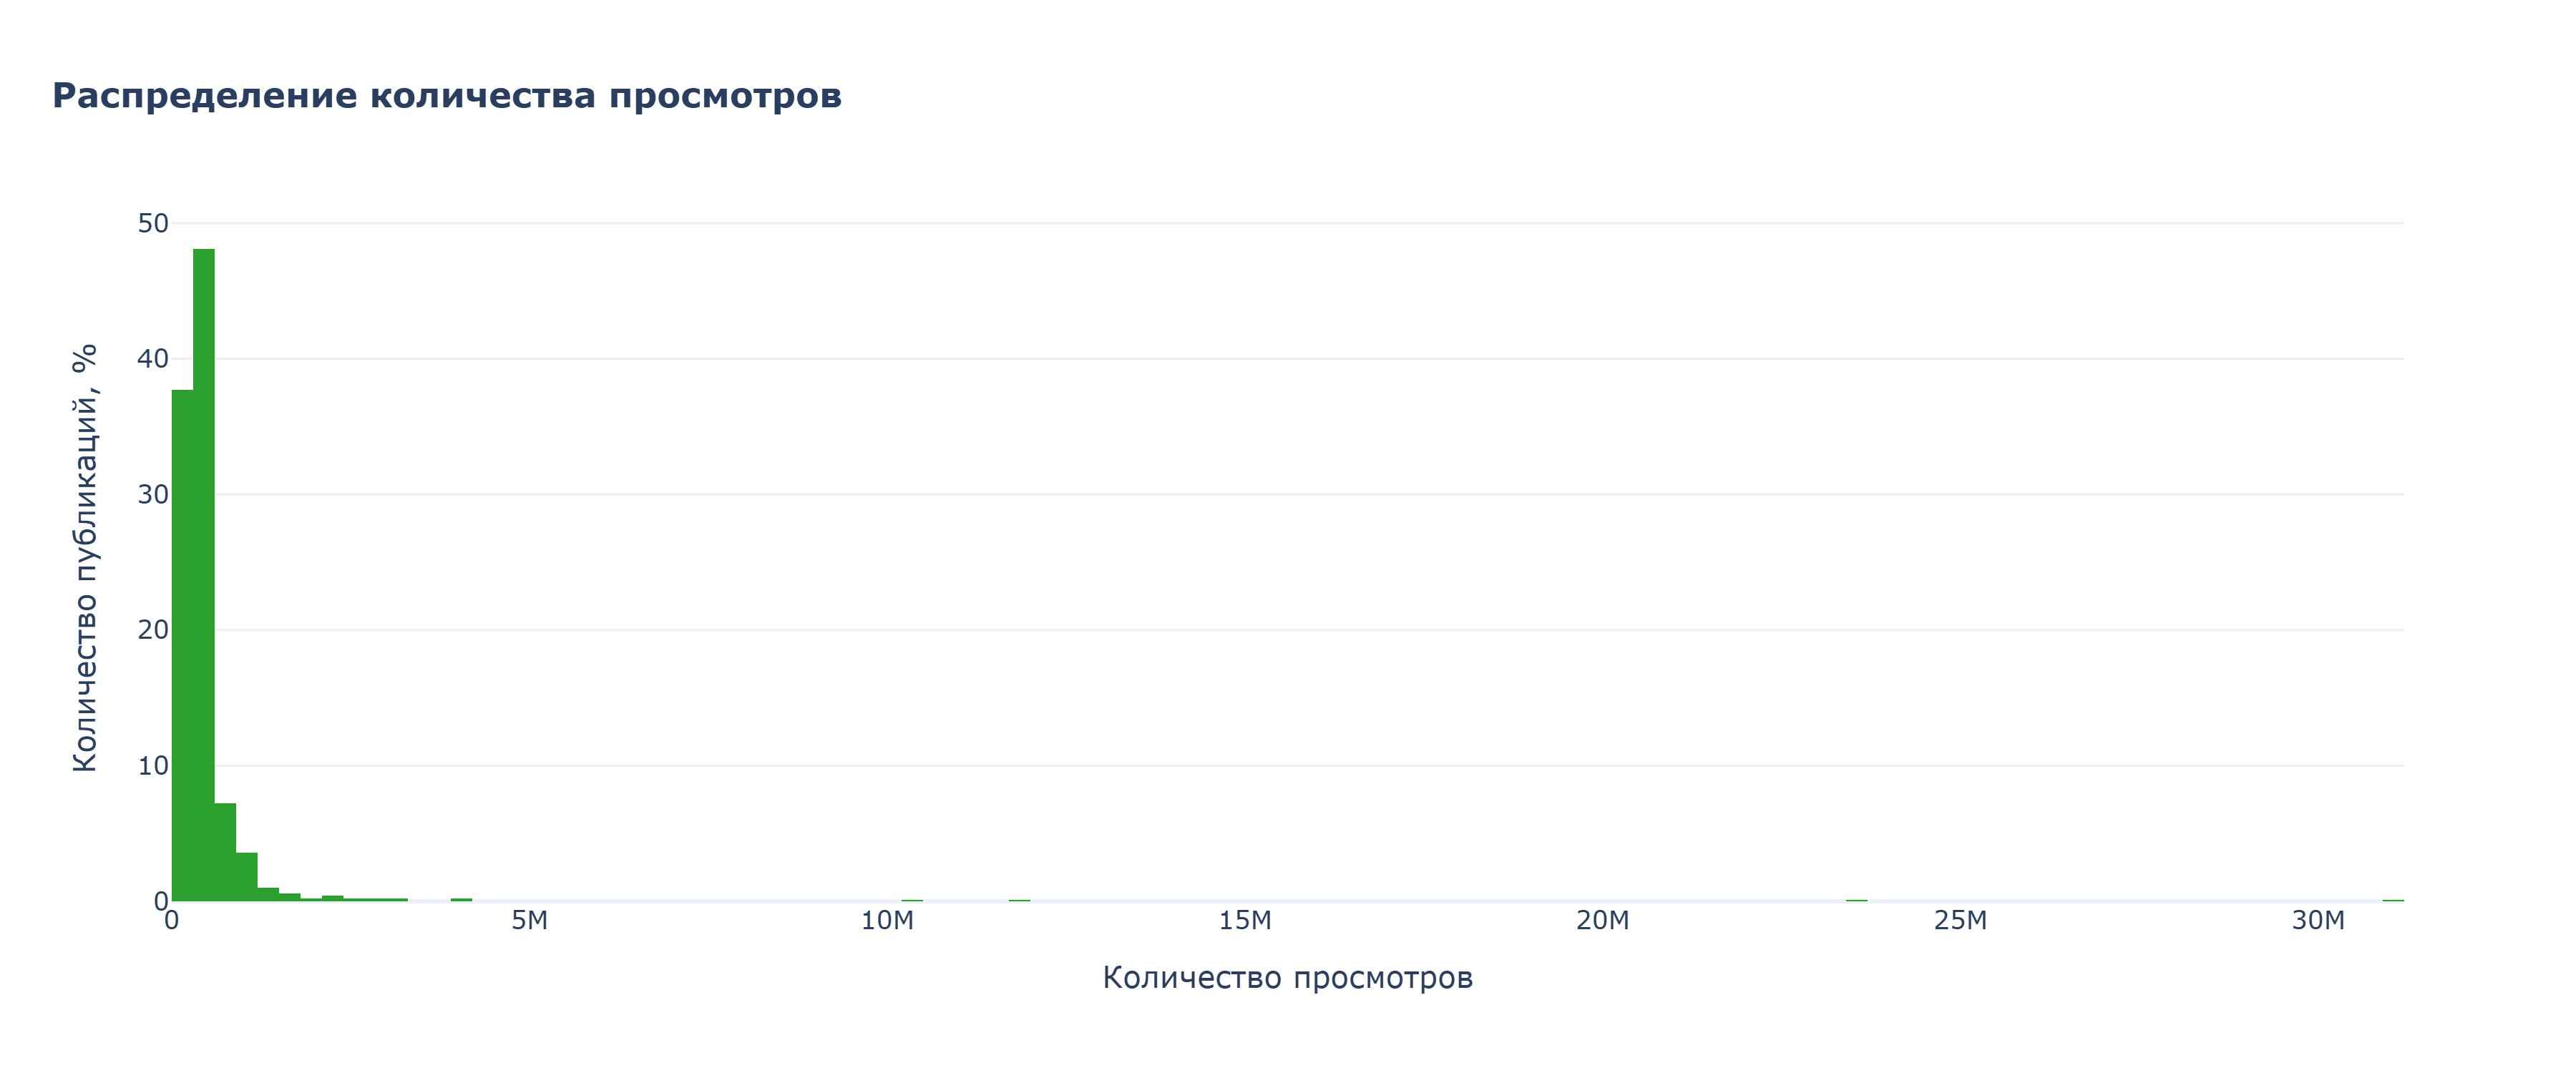

In [96]:
fig = go.Figure()

fig.add_trace(go.Histogram(x=df['views_count'],
                           y=df['post_id'],
                           marker_color=plotly.colors.qualitative.D3[2],
                           histnorm='percent',
                           name='',
                           xbins=dict(start=0, size=300000),
                           hovertemplate='Интервал просмотров: %{x}<br>Процент публикаций: %{y}<extra></extra>'
                           )

)

fig.update_layout(
    title=dict(
        text='<b>Распределение количества просмотров</b>', 
        x=0.02, 
        xanchor='left', 
        font=dict(
            size=16)
            )
)

fig.update_xaxes(title=dict(text='Количество просмотров'))
fig.update_yaxes(title=dict(text='Количество публикаций, %'))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

Количество просмотров имеет лог-нормальное распределение. Около 86% всех публикаций набирают до 600 тыс. просмотров. Также гистограмма указывает на то, что есть сильные выбросы.

Так как гистограмма имеет длинный правый хвост можно ввести в анализ логарифм просмотров. Это снизит влияние на средние значения виральных постов.

In [97]:
df['log_views'] = np.log1p(df['views_count'])

Данные выбросы хорошо видно на графике boxplot. Для дальнейшего анализа следует использовать медиану вместо среднего значения, поскольку медиана менее чувствительна к выбросам. В дальнейшем имеет смысл отдельно изучить данные наблюдения, тк. они могут дать сильные выводы о том, какие посты "заходят" аудитории.

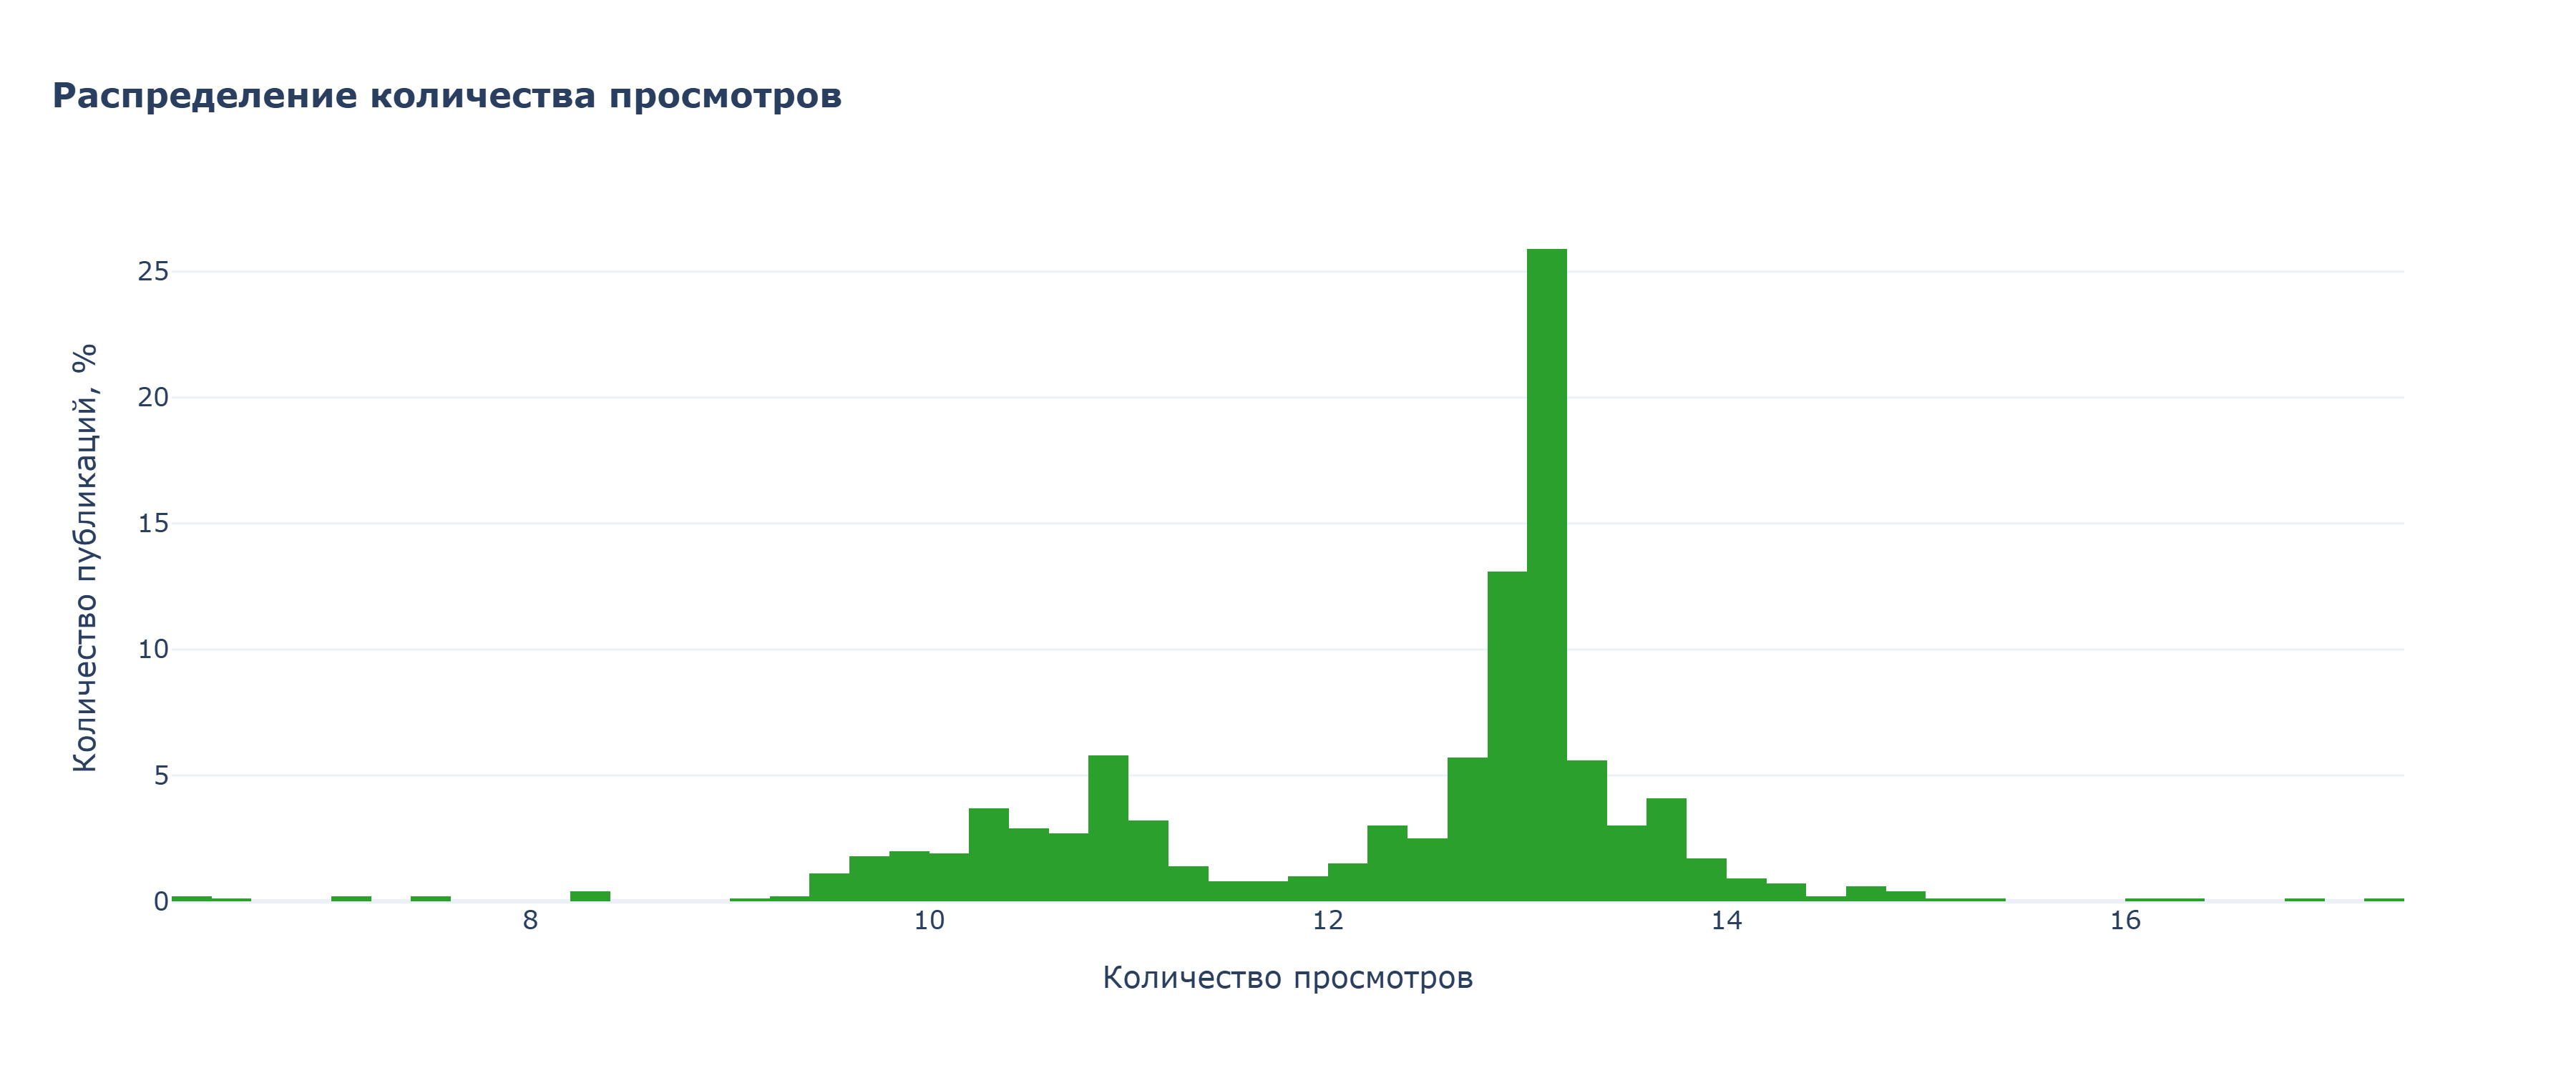

In [98]:
fig = go.Figure()

fig.add_trace(go.Histogram(x=df['log_views'],
                           y=df['post_id'],
                           marker_color=plotly.colors.qualitative.D3[2],
                           histnorm='percent',
                           name='',
                           #xbins=dict(start=0, size=300000),
                           hovertemplate='Интервал просмотров: %{x}<br>Процент публикаций: %{y}<extra></extra>'
                           )

)

fig.update_layout(
    title=dict(
        text='<b>Распределение количества просмотров</b>', 
        x=0.02, 
        xanchor='left', 
        font=dict(
            size=16)
            )
)

fig.update_xaxes(title=dict(text='Количество просмотров'))
fig.update_yaxes(title=dict(text='Количество публикаций, %'))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

Даже после логарифмирования распределение остается скошенным

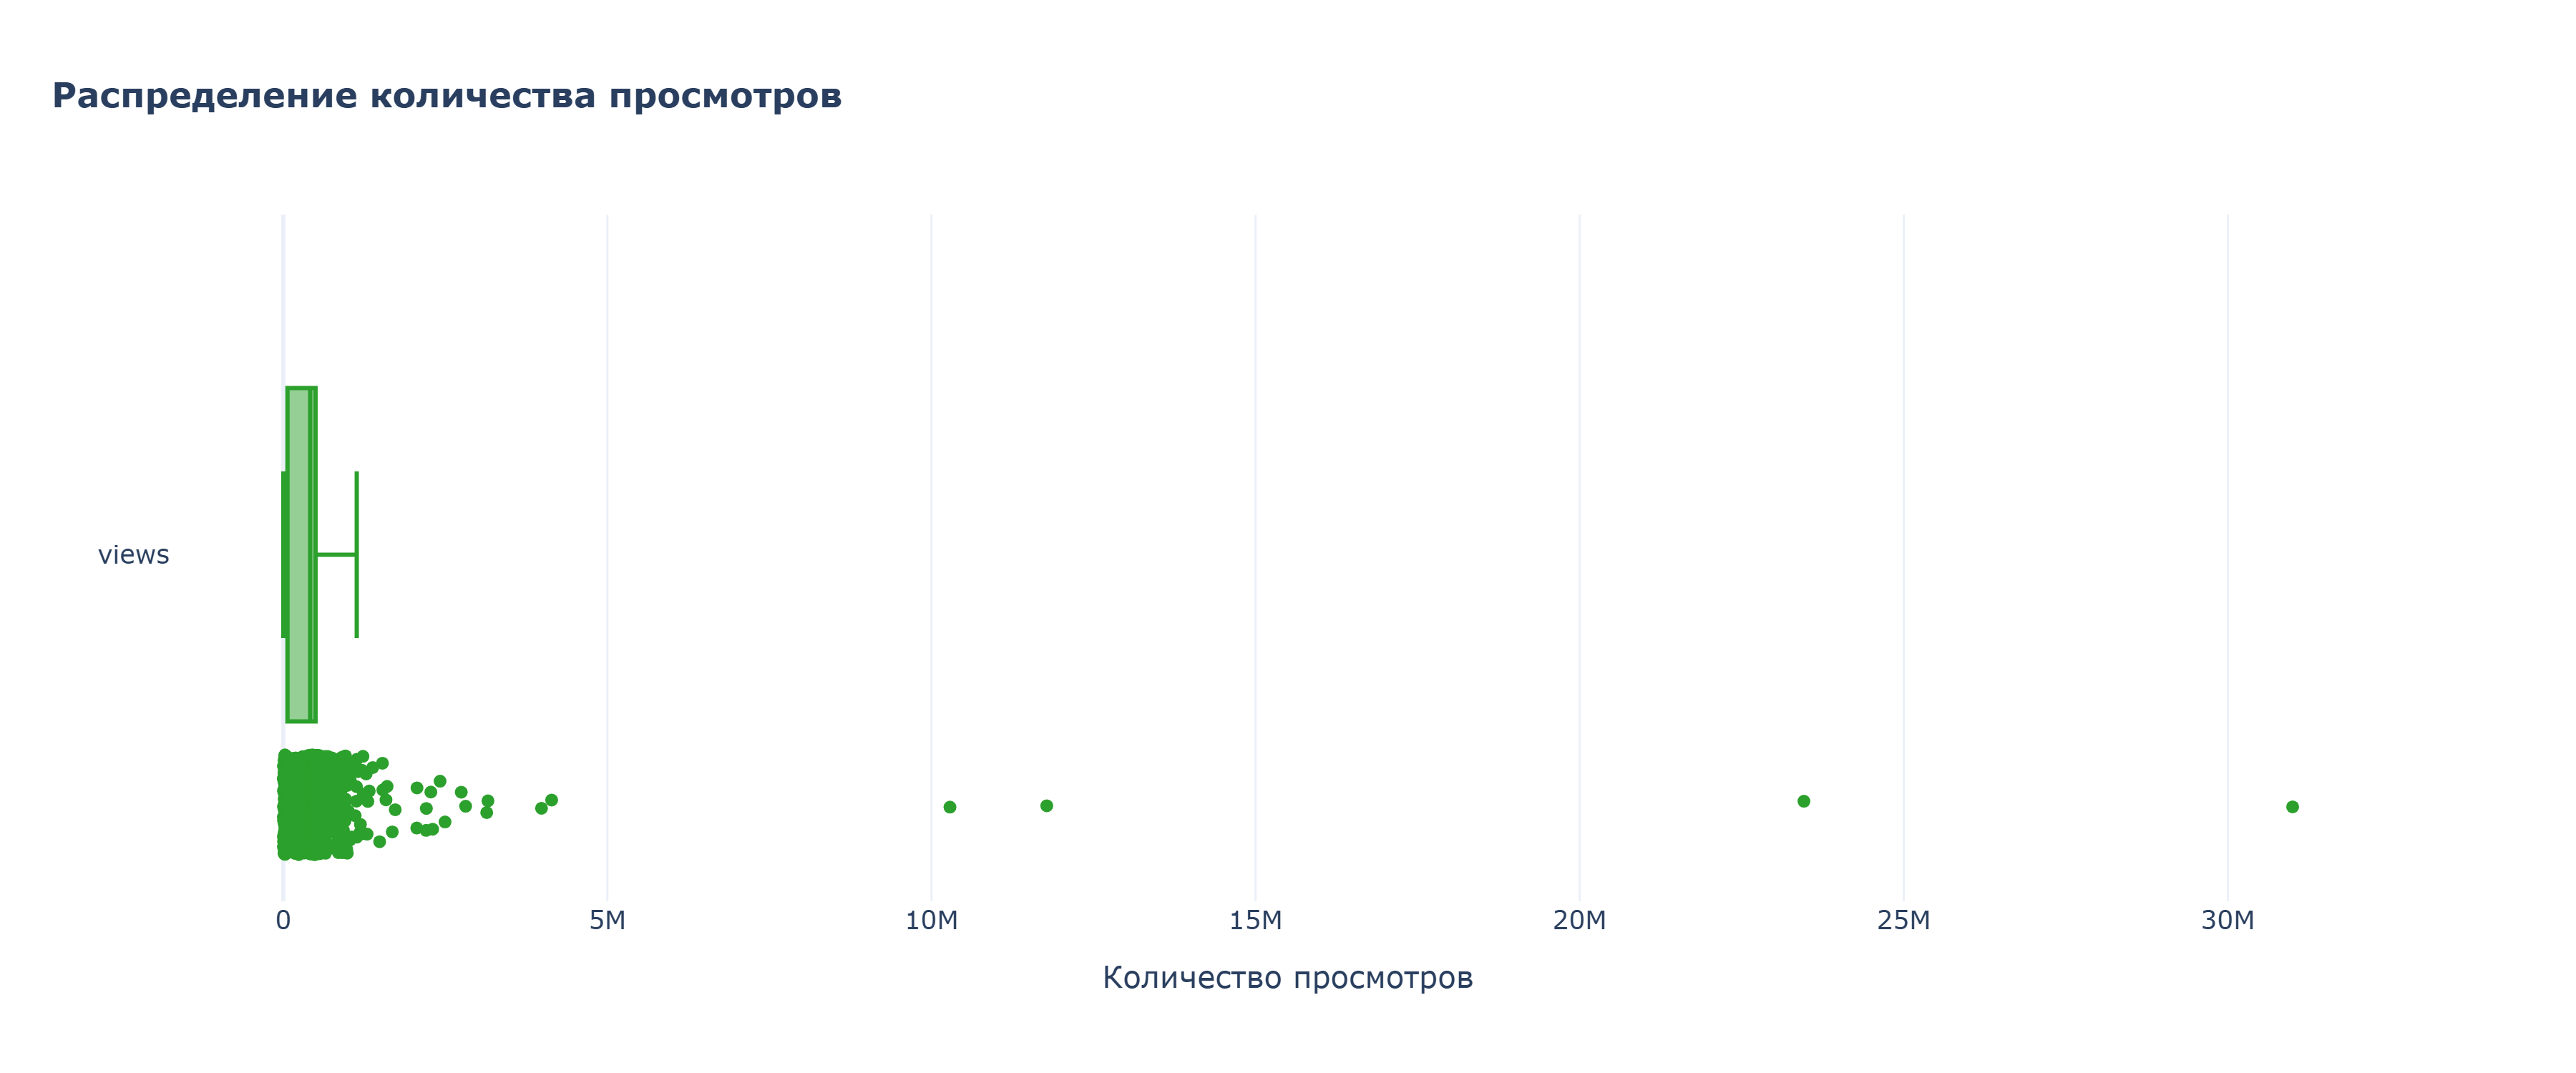

In [99]:
fig = go.Figure()

fig.add_trace(go.Box(x=df['views_count'],
                     marker_color=plotly.colors.qualitative.D3[2],
                     name='views',
                     boxpoints='all',
                     )
)

fig.update_layout(
    title=dict(
        text='<b>Распределение количества просмотров</b>', 
        x=0.02, 
        xanchor='left', 
        font=dict(
            size=16)
            )
)

fig.update_xaxes(title=dict(text='Количество просмотров'))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

## Выбросы

Отдельно маркируем выбросы снизу и сверху. По возможности, к ним можно будет вернуться и изучить как виральные посты.

In [100]:
df['is_outlier'] = ''

In [101]:
# выбросы определяю, как 2.5% значений слева и справа 
upper_mask = df['views_count'] > df['views_count'].quantile(0.975)
lower_mask = df['views_count'] < df['views_count'].quantile(0.025)
empty_mask = df['is_outlier'] == ''

In [102]:
df.loc[lower_mask, 'is_outlier'] = 'lower'

In [103]:
df.loc[empty_mask, 'is_outlier'] = 'no'
df.loc[upper_mask, 'is_outlier'] = 'upper'
df.loc[lower_mask, 'is_outlier'] = 'lower'

In [104]:
# доля выбросов от всех постов
len(df[df['is_outlier'].isin(['lower', 'upper'])]) / len(df)

0.05

In [105]:
# вклад верхних выбросов в общий объём просмотров
(df[df['is_outlier'] == 'upper']['views_count'].sum() / df['views_count'].sum()).round(2)

0.26

In [106]:
df[df['is_outlier'] == 'upper']['day_name'].value_counts()

day_name
Tuesday      6
Wednesday    5
Friday       4
Thursday     4
Monday       3
Sunday       2
Saturday     1
Name: count, dtype: int64

In [107]:
df[df['is_outlier'] == 'lower']['day_name'].value_counts()

day_name
Saturday     9
Sunday       4
Friday       4
Monday       3
Wednesday    2
Tuesday      2
Thursday     1
Name: count, dtype: int64

Меньше всего постов с высокими просмотрами приходится на выходные. Больше всего постов с низкими просмотрами, наоборот, приходится на субботу и воскресенье.

In [108]:
df[df['is_outlier'] == 'upper']['type'].value_counts()

type
video    24
photo     1
Name: count, dtype: int64

In [109]:
df[df['is_outlier'] == 'lower']['type'].value_counts()

type
video    16
photo     8
poll      1
Name: count, dtype: int64

# Влияние времени публикации поста на количество просмотров

In [110]:
df.head(3)

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,type,post_text,day_name,day_of_week,hour,len_post_text,hours_since_prev_post,log_views,is_outlier
0,2369346,2026-08-30 16:48:05,32,7,10926,2,photo,"Камчатка, встречай «Школу 21» В год своего 1...",Sunday,7,16,1679,4.78,9.298992,lower
1,2369327,2026-08-30 12:00:59,18,8,9626,5,photo,"Специалисты Сбера вернулись в вуз, но уже в др...",Sunday,7,12,586,18.51,9.172327,lower
2,2369286,2026-08-29 17:30:34,41,13,535,3,video,Одиссей мог бы вернуться домой за неделю — есл...,Saturday,6,17,606,1.84,6.284134,lower


In [111]:
df_hour_post = (df.
    groupby('hour', as_index=False).
    agg(
        post_count=('post_id', 'count'),
        median_views=('views_count', 'median'),
        mean_views=('views_count', 'mean')
        ).
    round(0).
    sort_values(by='hour', ascending=True)
)
df_hour_post

,hour,post_count,median_views,mean_views
0,7,1,3137899.0,3137899.0
1,8,2,370761.0,370761.0
2,9,64,406430.0,690839.0
3,10,89,389398.0,376569.0
4,11,93,463264.0,510276.0
5,12,88,411782.0,383770.0
6,13,90,440764.0,441789.0
7,14,81,407185.0,393543.0
8,15,89,421628.0,775221.0
9,16,80,417428.0,375032.0


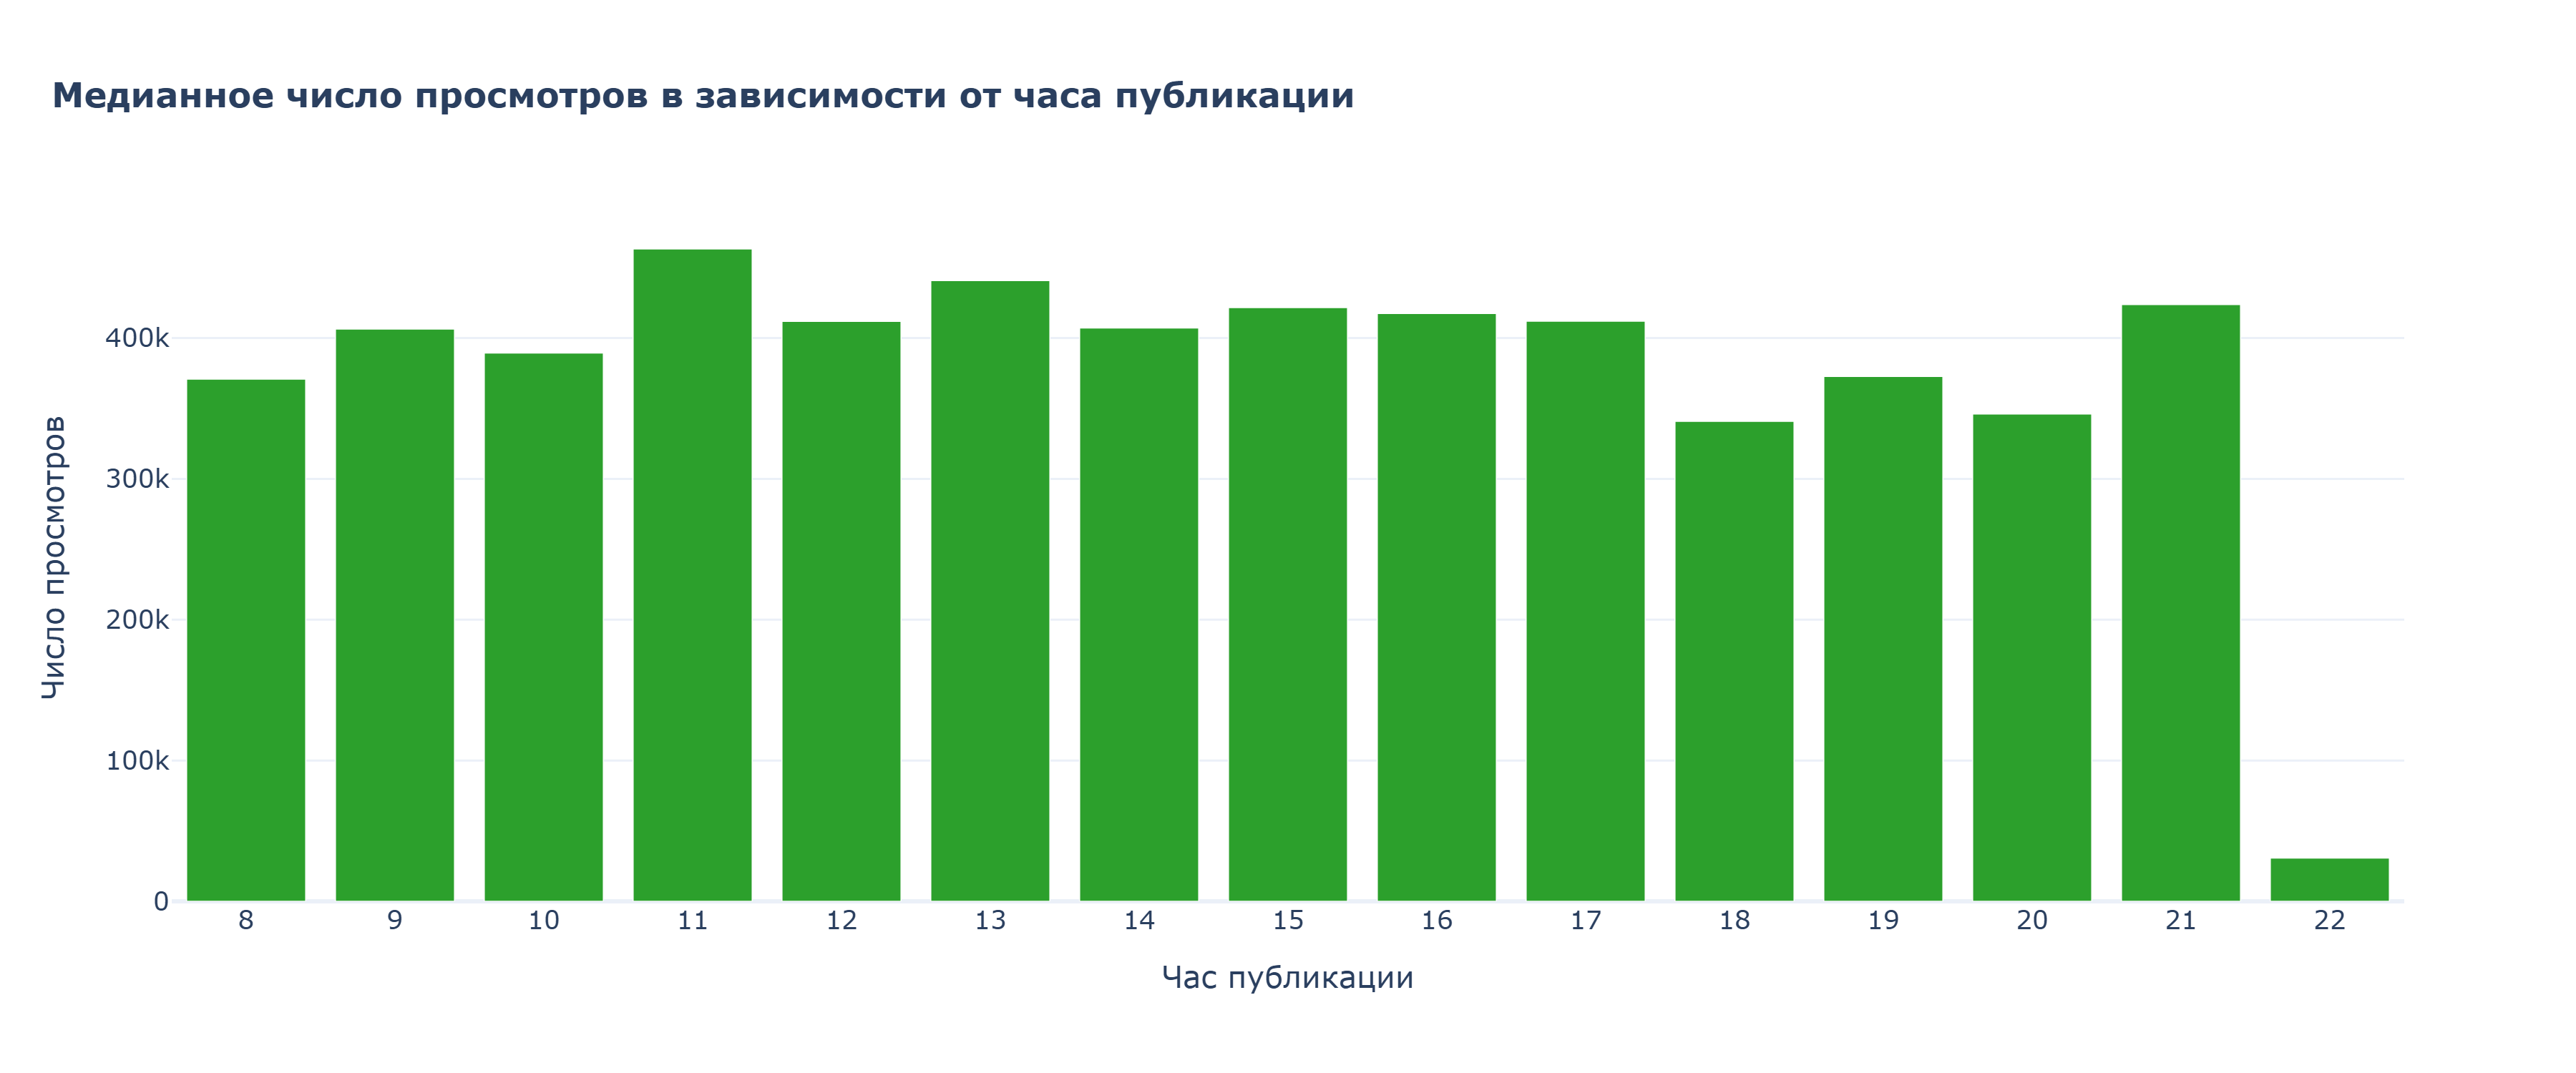

In [112]:
fig = go.Figure()

fig.add_trace(go.Bar(x=df_hour_post.iloc[1:, :]['hour'], # здесь намеренно исключаю один пост в 7 часов, чтобы график был более наглядным.
                     y=df_hour_post.iloc[1:, :]['median_views'],
                     name='',
                     marker_color=plotly.colors.qualitative.D3[2],
                     hoverinfo='all',
                     customdata=df_hour_post.iloc[1:, :]['post_count'].to_numpy(),
                     hovertemplate='Час: %{x}<br>Медианное число просмотров: %{y:,.0f}<br>Количество постов: %{customdata}<extra></extra>'
                     )
              )
fig.update_layout(
    title=dict(
        text='<b>Медианное число просмотров в зависимости от часа публикации</b>', 
        x=0.02,
        xanchor='left',
        font=dict(size=16)
        )

    )

fig.update_xaxes(
    title=dict(text='Час публикации', font_size=14),
    tickvals=df_hour_post.iloc[1:, :]['hour']
    )
fig.update_yaxes(title=dict(text='Число просмотров', font_size=14))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

Из графика видно, что в среднем больше всего просмотров собирают посты, опубликованные в 11 и 13 часов, меньше всего - в вечернее время, 18-20 часов. Посты в 7 часов не учитываем, поскольку это один пост, набравший много просмотров. Исходя из графика, можно сделать вывод, что час публикации влияет на количество просмотров.

In [113]:
hour_groups = df[['hour', 'log_views']].sort_values(by='hour', ascending=True).values

# Берем логарифм просмотров, чтобы исключить влияние выбросов
hour_groups = [group['log_views'].values for name, group in df.groupby('hour', observed=True) if len(group) > 0]
h, p = kruskal(*hour_groups)
print(f'{p:.4f} < 0.05, следовательно, нулевая гипотеза (о равенстве средних) отвергается: различия между группами статистически значимы.')

0.0325 < 0.05, следовательно, нулевая гипотеза (о равенстве средних) отвергается: различия между группами статистически значимы.


Тест Kruskal-Wallis показал p < 0.05, что подтверждает гипотезу о том, что час публикации вляет на просмотры.

Дополнительно можно сгруппировать время публикации в 4 блока

In [114]:
df['time_of_day'] = np.select(
        condlist=[(df['hour'] >= 0) & (df['hour']< 6),
                (df['hour'] >= 6) & (df['hour']< 12),
                (df['hour'] >= 12) & (df['hour']< 18),
                (df['hour'] >= 18) & (df['hour']< 24)
                ],
        choicelist=['01_night', '02_morning', '03_afternoon', '04_evening'],
        default='Другое'
)

In [115]:
df_pivot_time_of_day = (df.
 groupby('time_of_day', as_index=False).
 agg(
    median_views=('views_count', 'median'),
    mean_views=('views_count', 'mean'),
    post_count=('post_id', 'count')
    ).round(2)
)
df_pivot_time_of_day

,time_of_day,median_views,mean_views,post_count
0,02_morning,430355.0,518327.04,249
1,03_afternoon,423566.0,517496.16,512
2,04_evening,347640.0,337425.51,239


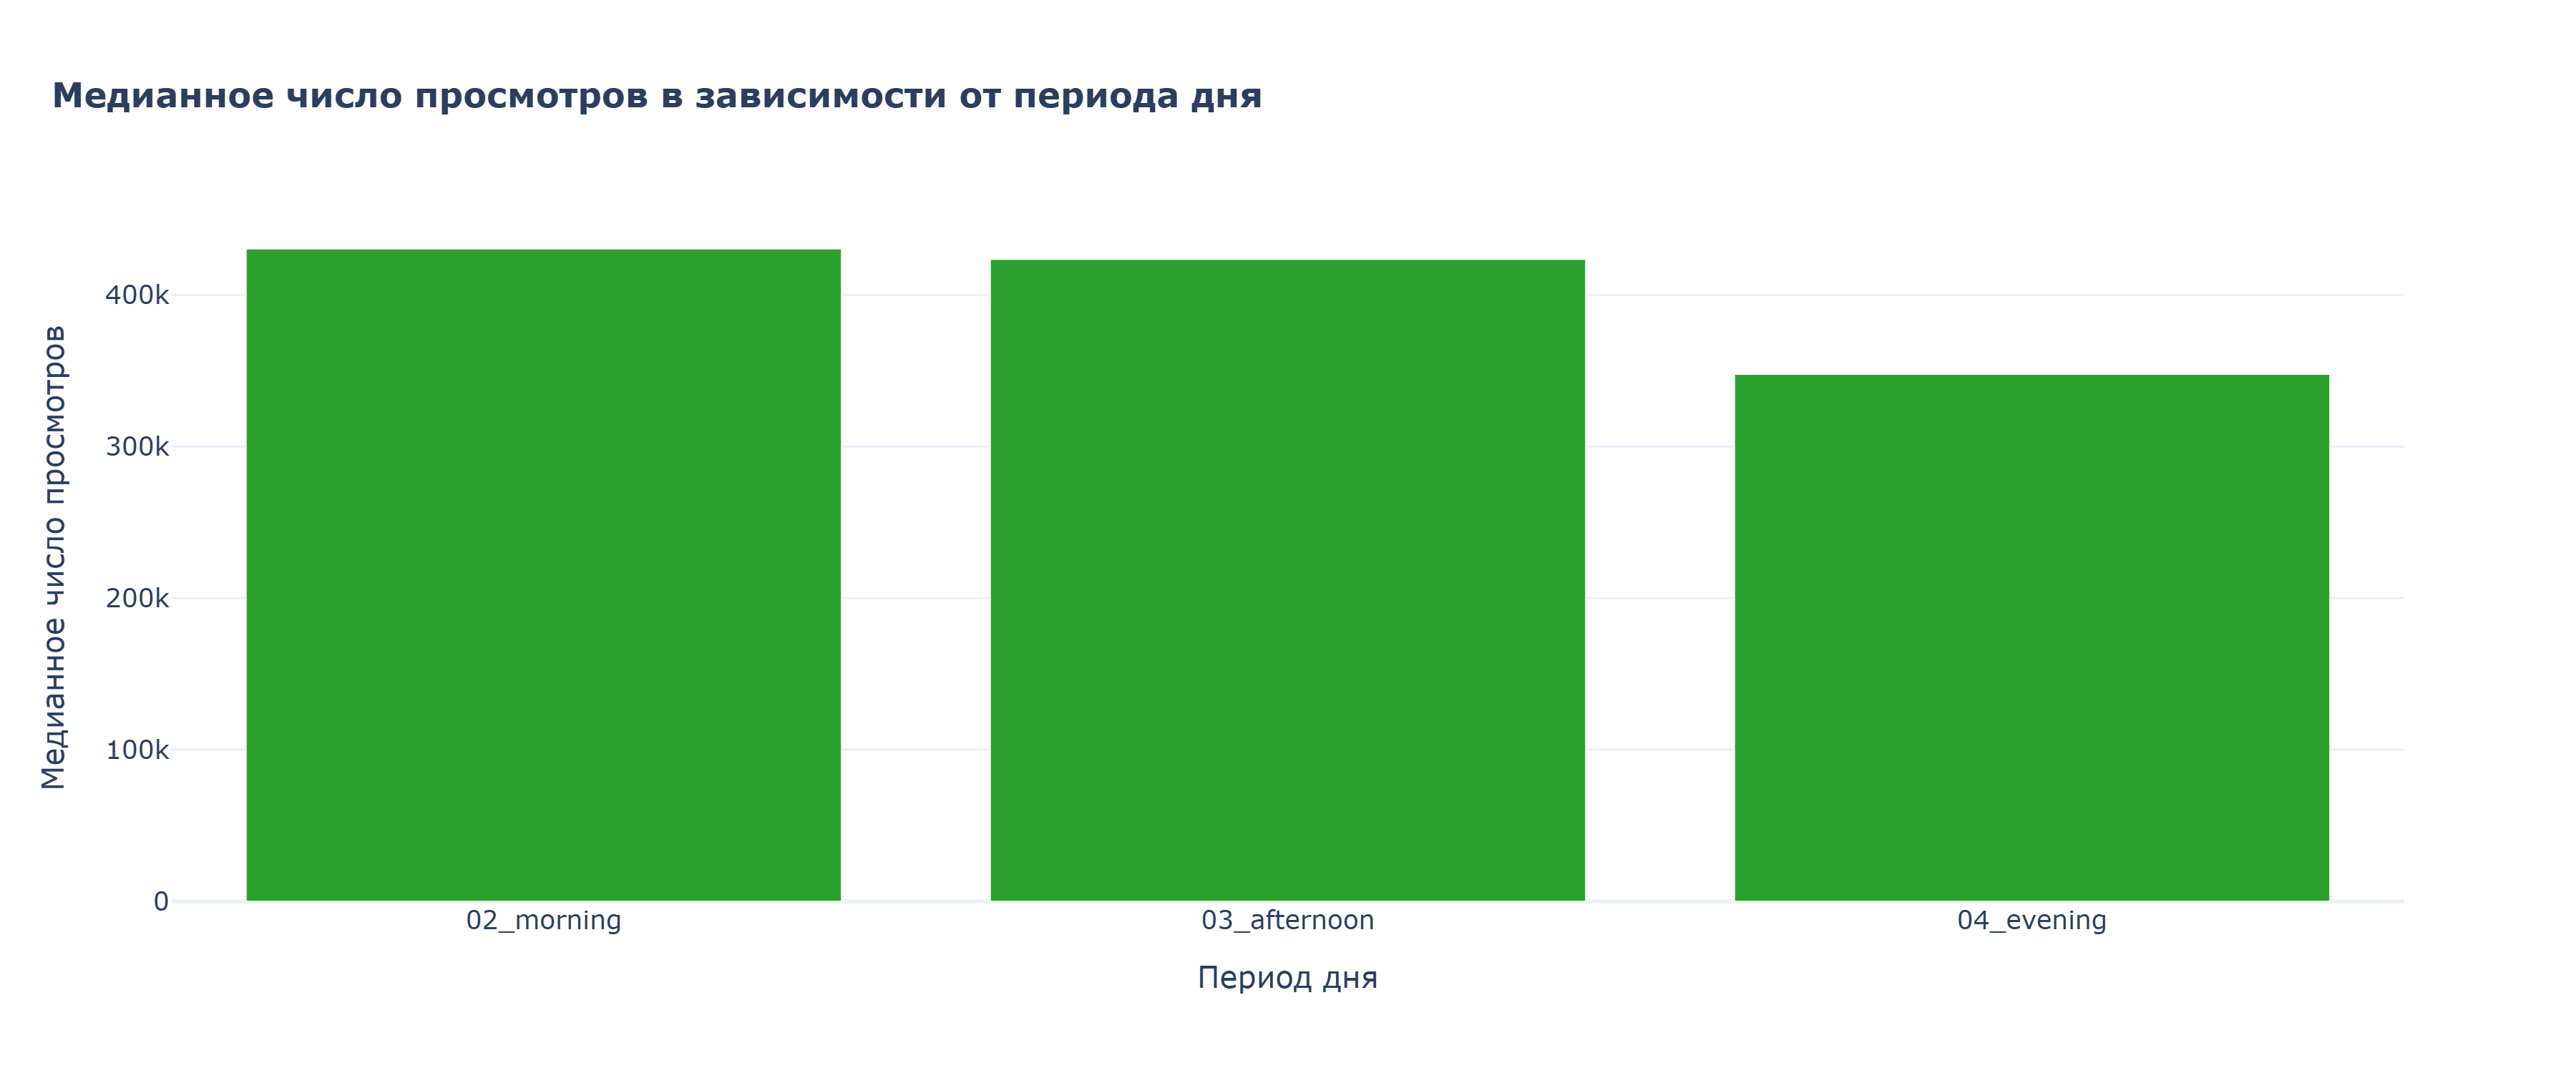

In [116]:
fig = go.Figure()

fig.add_trace(go.Bar(x=df_pivot_time_of_day['time_of_day'],
                     y=df_pivot_time_of_day['median_views'],
                     name='',
                     marker_color=plotly.colors.qualitative.D3[2],
                     hoverinfo='all',
                     hovertemplate='Медианное число просмотров: %{y:,.0f}')
              )
fig.update_layout(
    title=dict(
        text='<b>Медианное число просмотров в зависимости от периода дня</b>', 
        x=0.02,
        xanchor='left',
        font=dict(size=16)
        )
        )

fig.update_xaxes(title=dict(text='Период дня'))
fig.update_yaxes(title=dict(text='Медианное число просмотров'))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

Из графика видно, что в среднем больше всего просмотров приходится на дневное время (afternoon) и утреннее время (morning). Вечернее время (evening) сильно уступает первым двум по количеству просмотров. Посты в ночное время (night) не публикуются.

In [117]:
morning = df.loc[df['time_of_day'] == '02_morning', 'views_count']
afternoon = df.loc[df['time_of_day'] == '03_afternoon', 'views_count']
u, p = mannwhitneyu(morning, afternoon)

In [118]:
print(f'{p:.5f} > 0.05, следовательно, принимается нулевая гипотеза (о равенстве средних): различия статистически не значимы.')

0.69320 > 0.05, следовательно, принимается нулевая гипотеза (о равенстве средних): различия статистически не значимы.


Тест Mann-Whitney показал, что между утром и днем разницы нет, но они оба лучше вечера.

# Влияние дня недели публикации поста на количество просмотров

In [119]:
df.head(3)

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,type,post_text,day_name,day_of_week,hour,len_post_text,hours_since_prev_post,log_views,is_outlier,time_of_day
0,2369346,2026-08-30 16:48:05,32,7,10926,2,photo,"Камчатка, встречай «Школу 21» В год своего 1...",Sunday,7,16,1679,4.78,9.298992,lower,03_afternoon
1,2369327,2026-08-30 12:00:59,18,8,9626,5,photo,"Специалисты Сбера вернулись в вуз, но уже в др...",Sunday,7,12,586,18.51,9.172327,lower,03_afternoon
2,2369286,2026-08-29 17:30:34,41,13,535,3,video,Одиссей мог бы вернуться домой за неделю — есл...,Saturday,6,17,606,1.84,6.284134,lower,03_afternoon


In [120]:
df_pivot_day_of_week = (df.
 groupby(['day_name', 'day_of_week'], as_index=False).
 agg(
    median_views=('views_count', 'median'),
    mean_views=('views_count', 'mean'),
    post_count=('post_id', 'count')
    ).
 round(2).
 sort_values(by='day_of_week', ascending=True)
)
df_pivot_day_of_week

,day_name,day_of_week,median_views,mean_views,post_count
1,Monday,1,427068.0,542435.79,160
5,Tuesday,2,443828.5,450251.09,160
6,Wednesday,3,395743.0,468086.31,157
4,Thursday,4,391182.0,528032.33,195
0,Friday,5,416535.0,424230.16,185
2,Saturday,6,436851.0,402184.34,91
3,Sunday,7,465316.5,467289.50,52


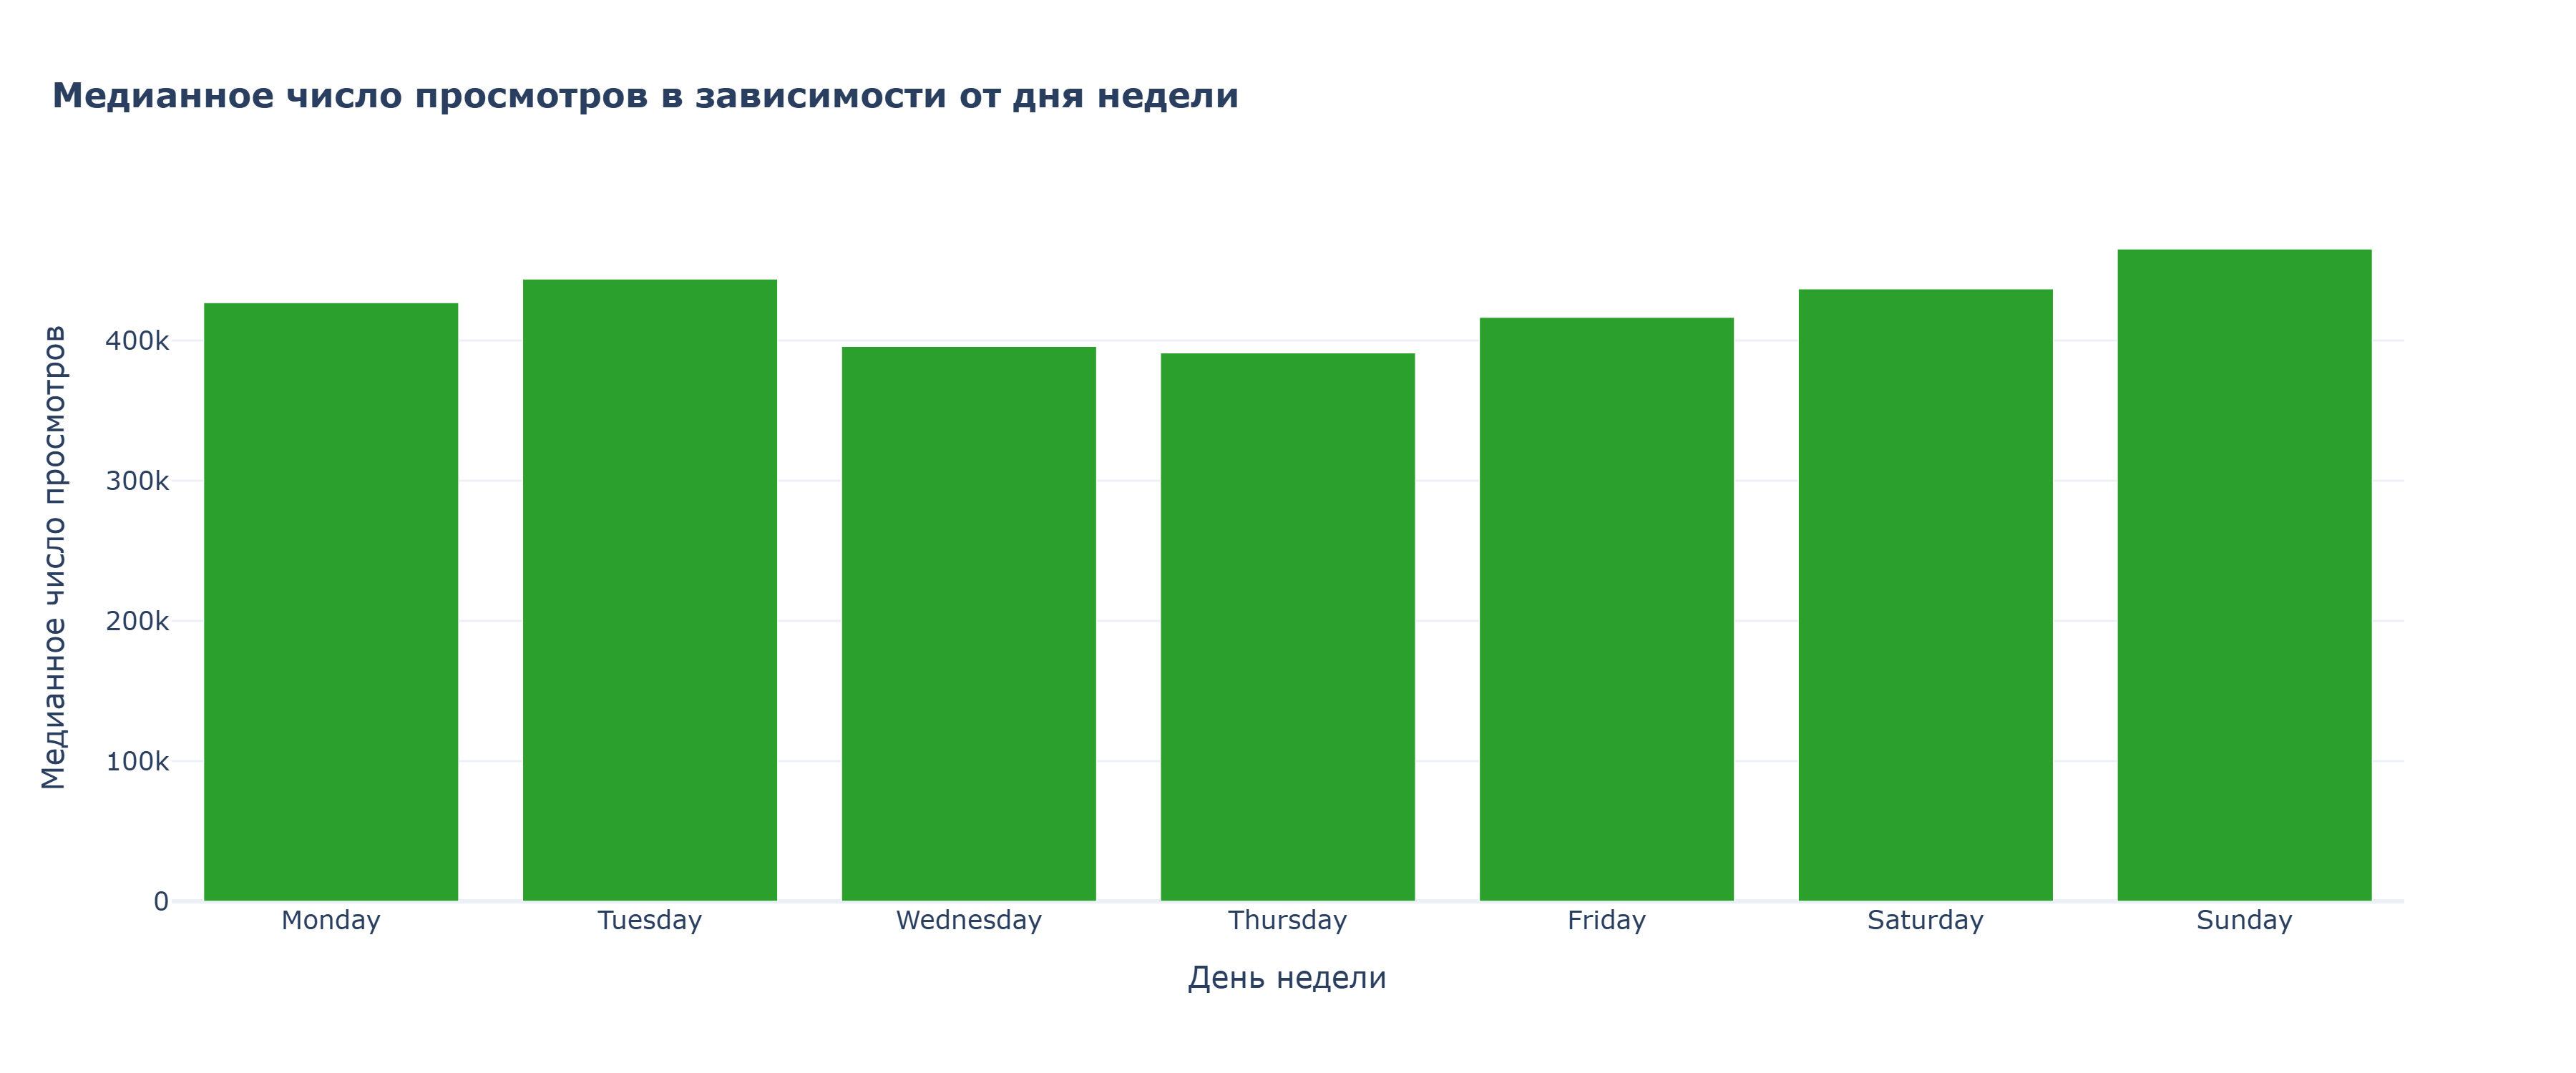

In [121]:
fig = go.Figure()

fig.add_trace(go.Bar(x=df_pivot_day_of_week['day_name'],
                     y=df_pivot_day_of_week['median_views'],
                     name='',
                     marker_color=plotly.colors.qualitative.D3[2],
                     hoverinfo='all',
                     customdata=df_pivot_day_of_week['post_count'].to_numpy(),
                     hovertemplate='Медианное число просмотров: %{y:,.0f}<br>Количество просмотров: %{customdata}<extra></extra>')
              )

fig.update_layout(
    title=dict(
        text='<b>Медианное число просмотров в зависимости от дня недели</b>', 
        x=0.02,
        xanchor='left',
        font=dict(size=16)
        )
        )
fig.update_xaxes(title=dict(text='День недели'))
fig.update_yaxes(title=dict(text='Медианное число просмотров'))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

Из графика видно, что в среднем больше всего просмотров собирают посты, опубликованные во вторник, воскресенье. Однако разница по дням недели кажется небольшой.

In [122]:
groups = [group['log_views'].values for name, group in df.groupby('day_of_week', observed=True) if len(group) > 0]
h, p = kruskal(*groups)
print(f'{p:.4f} > 0.05, следовательно, нулевая гипотеза (о равенстве средних) остается: различия между группами статистически не значимы.')

0.6197 > 0.05, следовательно, нулевая гипотеза (о равенстве средних) остается: различия между группами статистически не значимы.


Тест Тест Kruskal-Wallis показал, что статистически значимых различий между днями недели не выявлено, аудитория ведет себя одинаково во все дни.

## Влияние дня недели и часа публикации поста на количество просмотров

In [123]:
df_pivot_time_of_day_and_hour = (df.
    groupby(['day_name', 'day_of_week', 'hour'], as_index=False).
    agg(
        median_views=('views_count', 'median'),
        mean_views=('views_count', 'mean'),
        post_count=('post_id', 'count')
        ).
    round(2)
)
df_pivot_time_of_day_and_hour

,day_name,day_of_week,hour,median_views,mean_views,post_count
0,Friday,5,7,3137899.0,3137899.00,1
1,Friday,5,8,108457.0,108457.00,1
2,Friday,5,9,31067.0,197287.90,10
3,Friday,5,10,433925.0,379073.15,20
4,Friday,5,11,457351.0,393508.47,17
...,...,...,...,...,...,...
88,Wednesday,3,17,441846.5,356539.00,16
89,Wednesday,3,18,380816.0,340212.00,17
90,Wednesday,3,19,300648.0,335656.69,16
91,Wednesday,3,20,418956.0,424891.60,5


In [124]:
# сводная таблица среднего количества просмотров по дням недели и часам 
df_pivot_median_views = (df_pivot_time_of_day_and_hour.pivot(
    index=['day_name', 'day_of_week'], columns='hour', values='median_views').
    fillna(0).
    stack().
    reset_index().
    rename(columns={0: 'median_views'}).
    sort_values(by=['day_of_week', 'hour'], ascending=[False, True])
    )
df_pivot_median_views

,day_name,day_of_week,hour,median_views
48,Sunday,7,7,0.0
49,Sunday,7,8,0.0
50,Sunday,7,9,935648.5
51,Sunday,7,10,43164.0
52,Sunday,7,11,649597.5
...,...,...,...,...
27,Monday,1,18,257074.0
28,Monday,1,19,455876.0
29,Monday,1,20,226621.0
30,Monday,1,21,262434.5


In [125]:
# Исключаем выброс для лучшей читаемости heatmap
df_pivot_median_views_filtered = df_pivot_median_views[~((df_pivot_median_views['day_name'] == 'Friday') & (df_pivot_median_views['hour'] == 7))]

In [126]:
# сводная таблица количества постов по дням недели и часам 
df_pivot_post_count = (df_pivot_time_of_day_and_hour.pivot(
    index=['day_name', 'day_of_week'], columns='hour', values='post_count').
    fillna(0).
    stack().
    reset_index().
    rename(columns={0: 'post_count'}).
    sort_values(by=['day_of_week', 'hour'], ascending=[False, True])
    )
df_pivot_post_count

,day_name,day_of_week,hour,post_count
48,Sunday,7,7,0.0
49,Sunday,7,8,0.0
50,Sunday,7,9,6.0
51,Sunday,7,10,6.0
52,Sunday,7,11,6.0
...,...,...,...,...
27,Monday,1,18,19.0
28,Monday,1,19,13.0
29,Monday,1,20,8.0
30,Monday,1,21,2.0


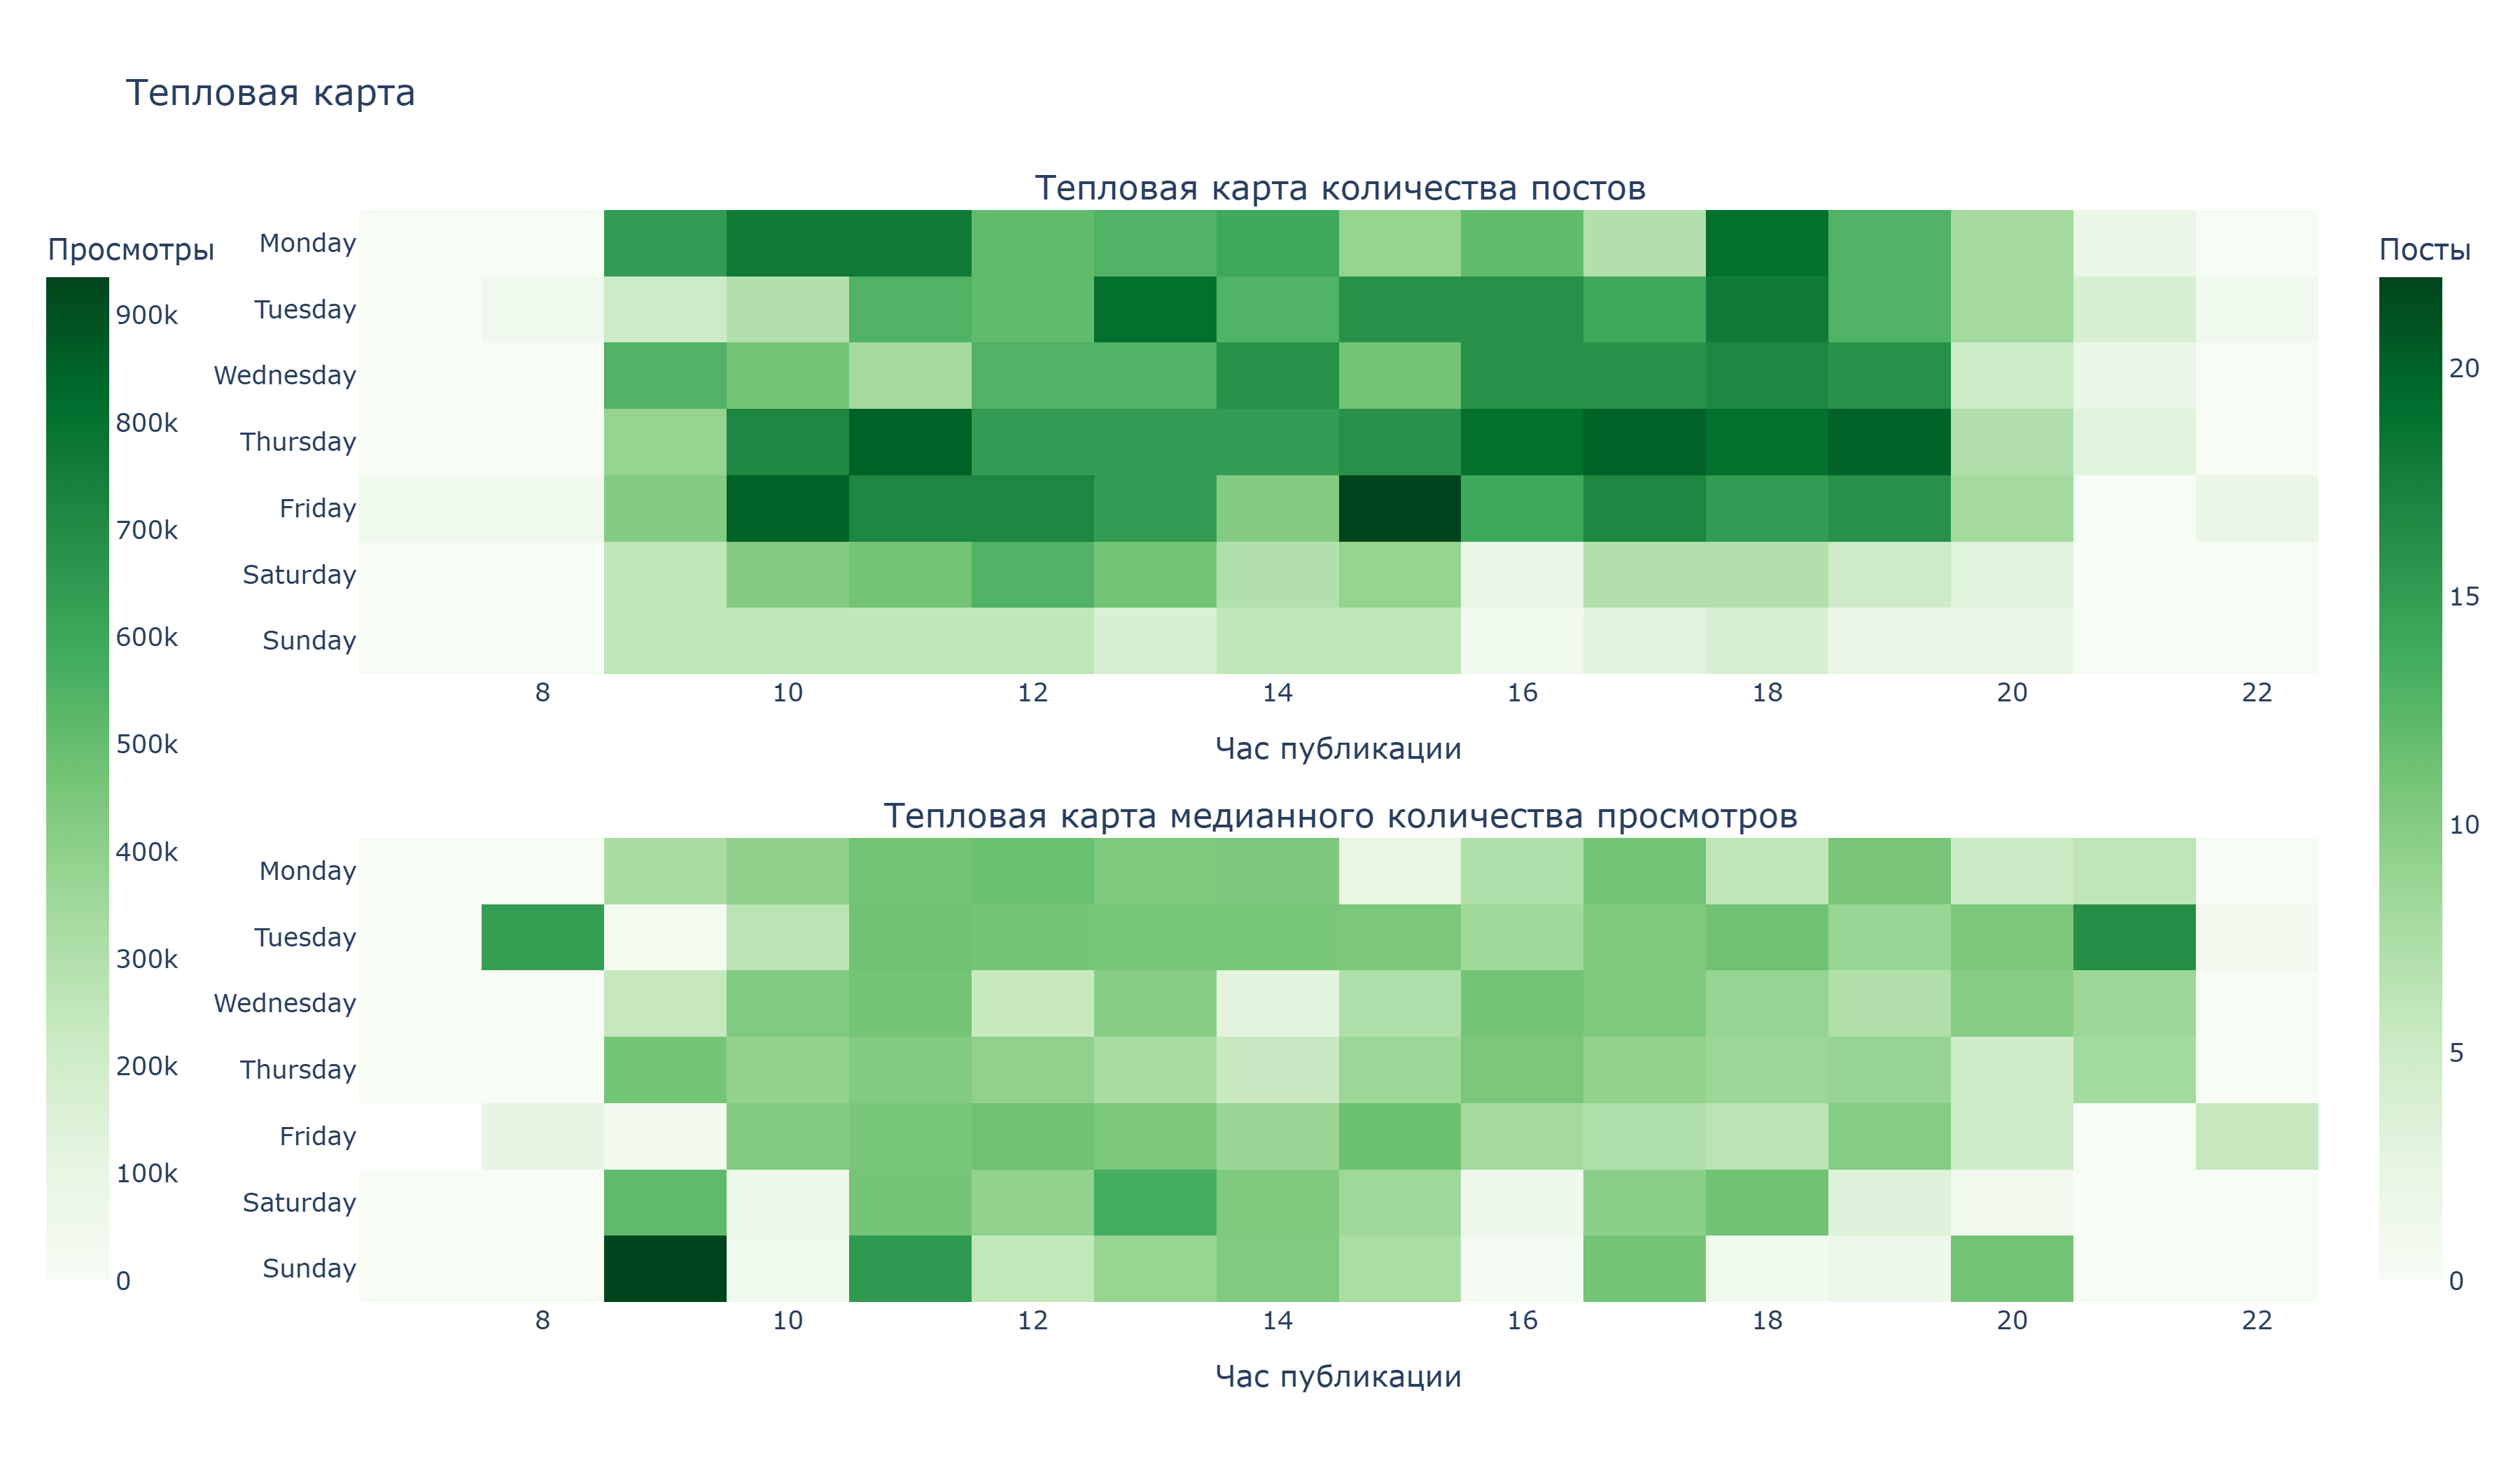

In [127]:
fig = make_subplots(rows=2, cols=1, 
                    subplot_titles=['Тепловая карта количества постов',
                                    'Тепловая карта медианного количества просмотров'],
                    vertical_spacing=0.15)

fig.add_trace(go.Heatmap(y=df_pivot_post_count['day_name'],
                         x=df_pivot_post_count['hour'],
                         z=df_pivot_post_count['post_count'],
                         name='',
                         colorscale=plotly.colors.sequential.Greens,
                         colorbar=dict(title='Посты', x=1.02),
                         hovertemplate='День публикации: %{y}<br>Час публикации: %{x}<br>Количество постов: %{z}'),
                         row=1, col=1
)

fig.add_trace(go.Heatmap(y=df_pivot_median_views_filtered['day_name'],
                         x=df_pivot_median_views_filtered['hour'],
                         z=df_pivot_median_views_filtered['median_views'],
                         name='',
                         colorscale=plotly.colors.sequential.Greens,
                         showscale=True,
                         colorbar=dict(title='Просмотры', x=-0.17),
                         hovertemplate='День публикации: %{y}<br>Час публикации: %{x}<br>Медианное количество просмотров: %{z:,.0f}'),
                         row=2, col=1
)

fig.update_layout(title=dict(text='Тепловая карта'), height=700)
fig.update_layout(title=dict(text='Тепловая карта'), height=700, hovermode='x')

fig.update_xaxes(title=dict(text='Час публикации'), showgrid=True)
fig.update_yaxes(title=dict(text=''), showgrid=False)

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

Верхняя карта (количество постов) показывает, когда команда SMM публикует публикации. С понедельника по пятницу активность публикации начинается с 9-10 часов и затухает к 20 часам. При этом, в выходные (Сб/Вс) публикуется меньше постов, чем в будние дни, но активность также начинается с 9 часов. 

Нижняя карта (медианное количество просмотров) показывает некоторые отклонения: 
- Воскресенье, 9:00: наибольшее количество просмотров в среднем, ~950 тыс. за 6 постов. Странный паттерн, выглядит не логично.
- Воскресенье, 11:00: также большое количество просмотров в среднем, ~649 тыс. за 6 постов.
- Вторник, 8:00: ~633 тыс. за 1 пост. Единичный случай, не паттерн.
- Вторник, 21:00: ~691 тыс. за 4 поста. Выглядит как отклонение он нормы, поскольку к 19-20 часам просмотры падают.

Здесь мы не можем сделать вывод об оптимальном времени публикации, это гипотеза. Рекомендация: протестировать данные слоты времени, поскольку они показывают высокие медианные охваты.

Посты в 11 и 13 часов имеют стабильно большое количество просмотров, независимо от дня недели, что также подтверждает тот факт, что час публикации влияет на просмотры (они выше в 11 и 13 часов).

Общая тенденция здесь такова, что в будние дни с 10:00 до 19:00 наблюдается высокая плотность публикаций (n~10-15 постов). Однако, одни и теже часы в разные дни дают разное количество просмотров. Например, 12 часов в Понедельник, Вторник и Среду. Рекомендация: для каждого дня недели сместить публикацию постов с часов, которые набирают мало просмотров, на такие часы, в которые просмотры наибольшие. Например, с 12 и 14 часов среды на 10, 11, 13, 16 часов.

# Влияние интервала между постами на количество просмотров

In [128]:
df.head(3)

,post_id,post_date,likes_count,comments_count,views_count,reposts_count,type,post_text,day_name,day_of_week,hour,len_post_text,hours_since_prev_post,log_views,is_outlier,time_of_day
0,2369346,2026-08-30 16:48:05,32,7,10926,2,photo,"Камчатка, встречай «Школу 21» В год своего 1...",Sunday,7,16,1679,4.78,9.298992,lower,03_afternoon
1,2369327,2026-08-30 12:00:59,18,8,9626,5,photo,"Специалисты Сбера вернулись в вуз, но уже в др...",Sunday,7,12,586,18.51,9.172327,lower,03_afternoon
2,2369286,2026-08-29 17:30:34,41,13,535,3,video,Одиссей мог бы вернуться домой за неделю — есл...,Saturday,6,17,606,1.84,6.284134,lower,03_afternoon


In [129]:
# разбиваем hours_since_prev_post на бины
df['interval_bins'] = pd.qcut(df['hours_since_prev_post'], 5)

In [130]:
df_interval = (df.
    groupby('interval_bins', as_index=False, observed=True).
    agg(
        median_views=('views_count', 'median'),
        mean_views=('views_count', 'mean'),
        post_count=('post_id', 'count'),
        median_log_views=('log_views', 'median'),
    ).
    round(0)
)
df_interval['interval_bins'] = df_interval['interval_bins'].astype(str)
df_interval

,interval_bins,median_views,mean_views,post_count,median_log_views
0,"(0.079, 1.5]",416066.0,495698.0,210,13.0
1,"(1.5, 2.524]",367504.0,337545.0,190,13.0
2,"(2.524, 5.508]",401894.0,564740.0,199,13.0
3,"(5.508, 18.5]",417259.0,502274.0,201,13.0
4,"(18.5, 116.94]",449601.0,466590.0,199,13.0


Таблица показывает, что median_views меняется от 367 504 до 449 601. Разница есть, но она небольшая.
median_log_views везде равен 13.0. Это значит, что если мы уберем влияние выбросов (виральных постов) через логарифм, то медиана просмотров вообще не меняется от интервала к интервалу. Таким образом, гипотеза H3 (что слишком часто — плохо, и слишком редко — плохо) на данных не подтверждается, предполагаемая U-образную связь отсутствует - нет роста посередине. Медианы скачут: 416к -> 367к -> 401к -> 417к -> 449к, что не похоже на «эффект пресыщения».

In [131]:
df['interval_bins'] = df['interval_bins'].astype(str)

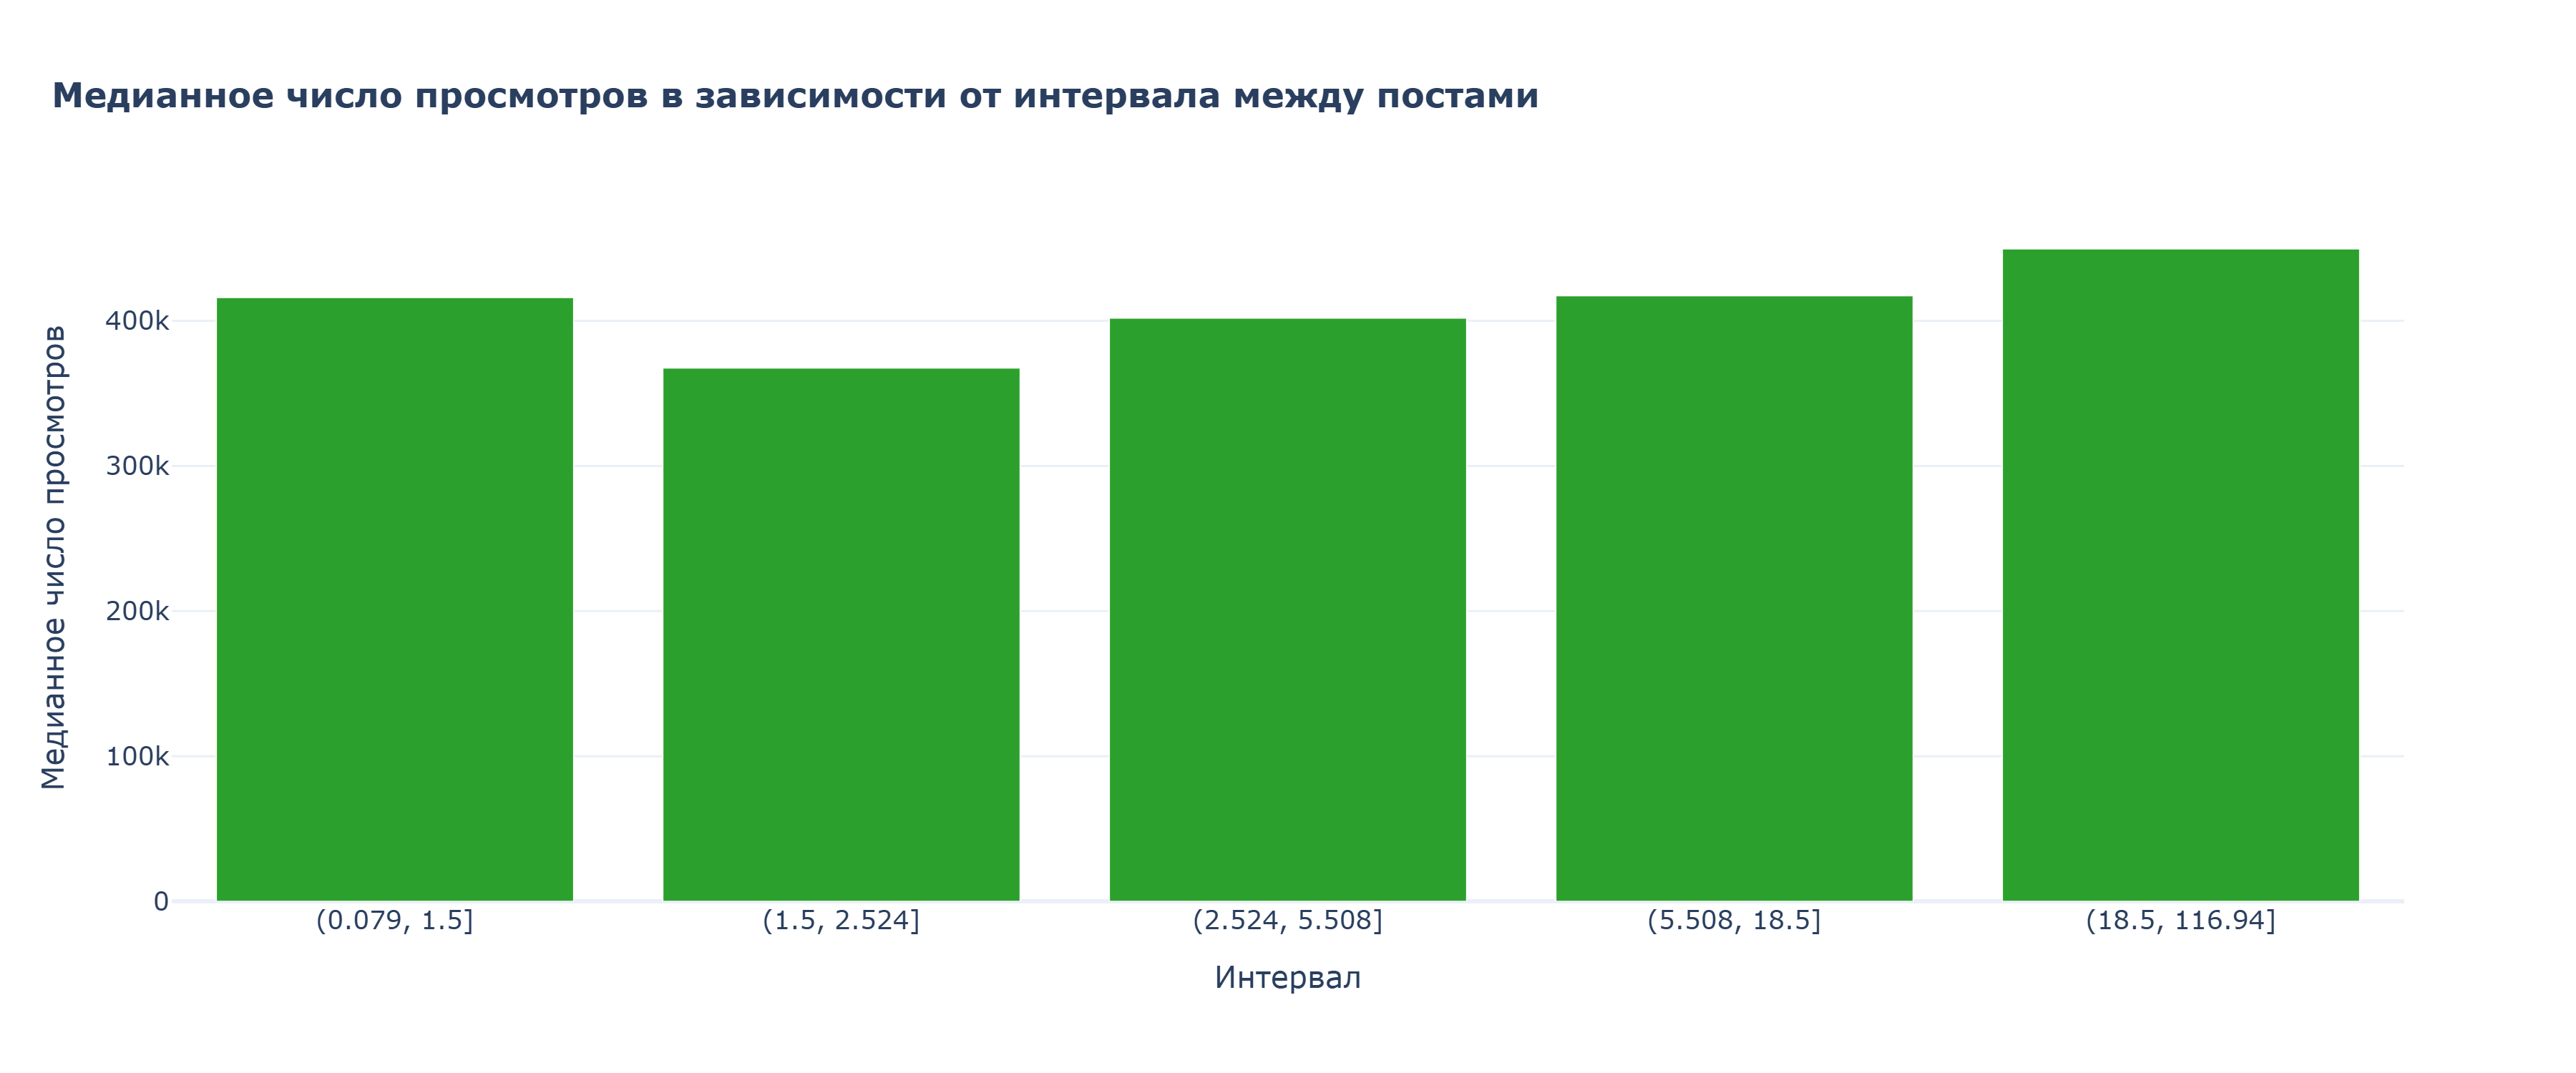

In [132]:
fig = go.Figure()

fig.add_trace(go.Bar(x=df_interval['interval_bins'],
                     y=df_interval['median_views'],
                     name='',
                     marker_color=plotly.colors.qualitative.D3[2],
                     hoverinfo='all',
                     customdata=df_interval['post_count'].to_numpy(),
                     hovertemplate='Медианное число просмотров: %{y:,.0f}<br>Количество просмотров: %{customdata}<extra></extra>')
              )

fig.update_layout(
    title=dict(
        text='<b>Медианное число просмотров в зависимости от интервала между постами</b>', 
        x=0.02,
        xanchor='left',
        font=dict(size=16)
        )
        )
fig.update_xaxes(title=dict(text='Интервал'))
fig.update_yaxes(title=dict(text='Медианное число просмотров'))

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

In [133]:
groups = [group['log_views'].values for name, group in df.groupby('interval_bins', observed=True) if len(group) > 0]
h, p = kruskal(*groups)
print(f'{p:.4f} > 0.05, следовательно, нулевая гипотеза (о равенстве средних) остается: различия между группами статистически не значимы.')

0.0826 > 0.05, следовательно, нулевая гипотеза (о равенстве средних) остается: различия между группами статистически не значимы.


Тест Тест Kruskal-Wallis показывает, что промежуток между постами не влияет на просмотры

In [134]:
groups = [group['log_views'].values for name, group in df.groupby('interval_bins', observed=True) if len(group) > 0]
kruskal(*groups)

KruskalResult(statistic=9.750691583153742, pvalue=0.08261546266117471)

# Сравнительная сводка

Финальная проверка гипотезы H4: среди трёх факторов хотя бы один вносит статистически значимый вклад.

In [135]:
def kruskal_report(df, factor_column, target_column='log_views'):
    groups = [group[target_column].values for name, group in df.groupby(factor_column, observed=True)]
    groups = [g for g in groups if len(g) >= 3]   # отсекаем n<3, одиночные посты
    h, p = kruskal(*groups)
    n = sum(len(group) for group in groups) # подсчет количества наблюдений для фактора
    k = len(groups) # подсчет количества групп для фактора
    eta2 = (h - k + 1) / (n - k) # доля объясненной дисперсии
    return {'factor': factor_column, 'H': h, 'p': p, 'eta2': eta2, 'n_groups': k, 'n': n}

results = pd.DataFrame([
    kruskal_report(df, 'hour'),
    kruskal_report(df, 'day_of_week'),
    kruskal_report(df, 'interval_bins'),
]).round(4)
results

,factor,H,p,eta2,n_groups,n
0,hour,23.5446,0.0356,0.0107,14,997
1,day_of_week,4.4228,0.6197,-0.0016,7,1000
2,interval_bins,9.4777,0.0502,0.0055,5,999


Также посчитаем spread (разброс). Мы берем самый удачный час (максимальная медиана) и самый неудачный (минимальная медиана) и вычитаем одно из другого. Тогда, например, если у Часа разброс 100 000 просмотров, а у Дня недели 20 000, то наглядно видно, что Час влияет сильнее.

In [136]:
def factor_spread(df, factor_column, target_column='log_views'):
    med = df.groupby(factor_column, observed=True)[target_column].median()
    counts = df.groupby(factor_column, observed=True)[target_column].count()
    med = med[counts >= 3]  # отсекаем редкие группы
    return {
        'factor': factor_column,
        'n_groups_kept': len(med),
        'min_median': med.min(),
        'max_median': med.max(),
        'spread': med.max() - med.min(),
        'best_group': med.idxmax(),
        'worst_group': med.idxmin(),
    }

spread_df = pd.DataFrame([
    factor_spread(df, 'hour'),
    factor_spread(df, 'day_of_week'),
    factor_spread(df, 'interval_bins'),
])

summary = results.merge(spread_df, on='factor')
summary

,factor,H,p,eta2,n_groups,n,n_groups_kept,min_median,max_median,spread,best_group,worst_group
0,hour,23.5446,0.0356,0.0107,14,997,14,10.331334,13.046055,2.714721,11,22
1,day_of_week,4.4228,0.6197,-0.0016,7,1000,7,12.876931,13.050475,0.173544,7,4
2,interval_bins,9.4777,0.0502,0.0055,5,999,5,12.813943,13.016118,0.202175,"(18.5, 116.94]","(1.5, 2.524]"


Финальная сводка показывает:
1. Hour (Час):
- p = 0.0325 (< 0.05). Влияние статистически значимо.
- eta2 = 0.0118. Размер эффекта хоть и небольшой (объясняет ~1.2% дисперсии), но он самый большой среди трех факторов.
- best_group = 11, worst_group = 22. Лучше всего постить в 11:00, хуже всего — в 22:00 вечера. Разброс (spread) — 2.71 (что существенно в логарифмах).

2. Day of week (День недели):
- p = 0.6197 (> 0.05). Влияние статистически не значимо.
- eta2 = -0.0016. Отрицательное значение означает, что эффекта нет вообще, это просто шум. Разброс (spread) минимальный — 0.17.

3. Interval bins (Интервал):
- p = 0.0826 (> 0.05), не влияет на уровне значимости 5%.
- eta2 = 0.0048. Эффект практически нулевой.

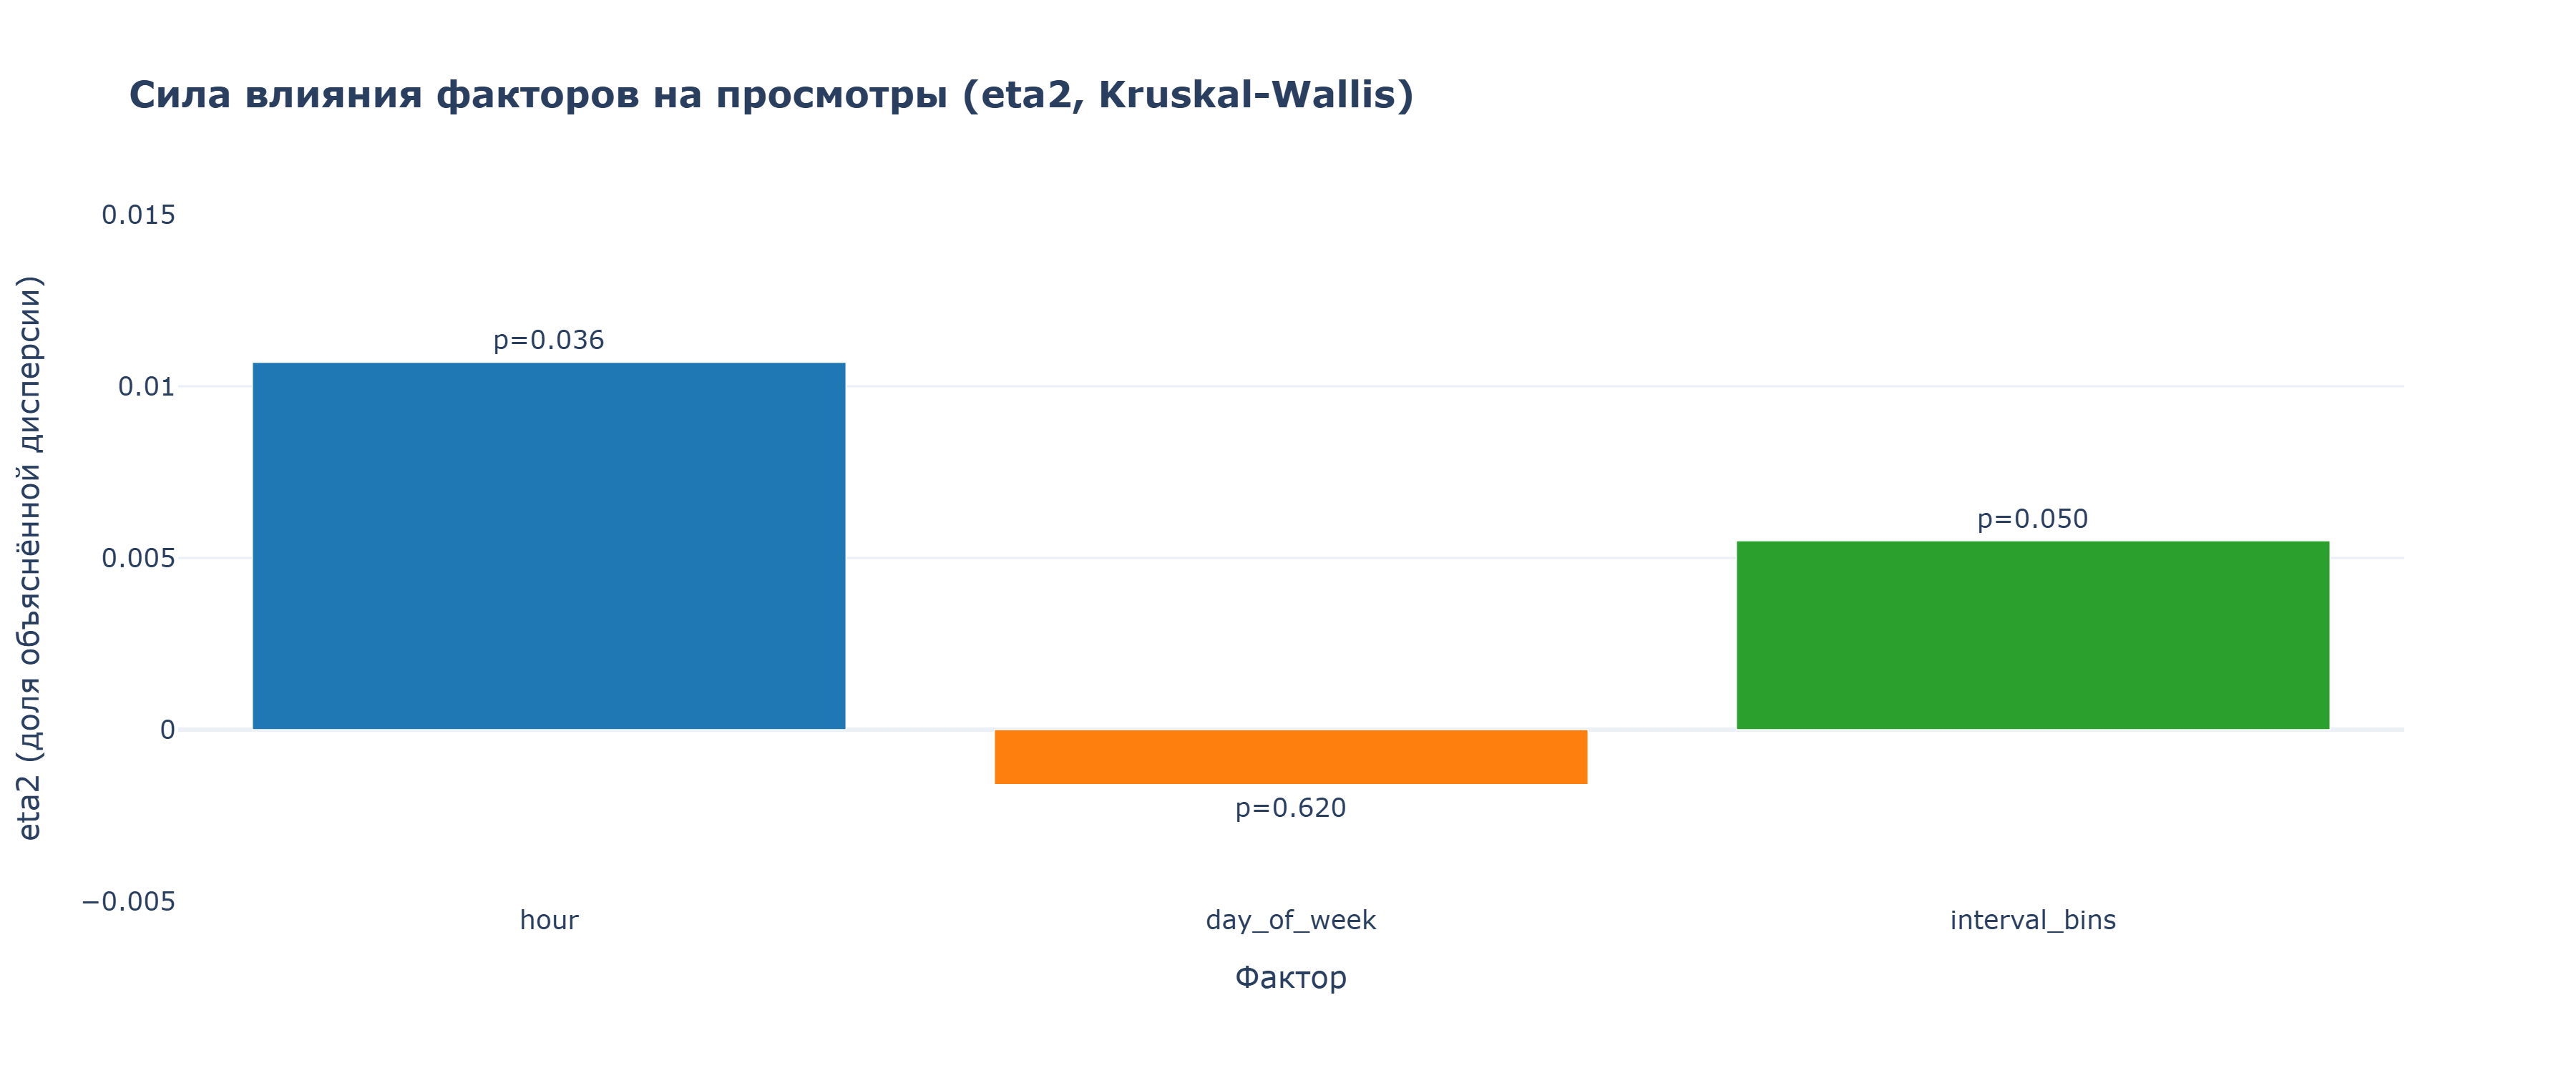

In [137]:
fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=summary['factor'],
        y=summary['eta2'],
        text=summary['p'].apply(lambda x: f'p={x:.3f}'),
        hovertemplate='Фактор: %{x}<br>eta2: %{y}<br>p-value: %{text}<extra></extra>',
        marker_color=plotly.colors.qualitative.D3
    )
)
fig.update_traces(textposition='outside')
fig.update_layout(
    title=dict(text='<b>Сила влияния факторов на просмотры (eta2, Kruskal-Wallis)</b>',
               xanchor='left')
)
fig.update_yaxes(
    title='eta2 (доля объяснённой дисперсии)',
    range=[-0.005, 0.015]
    )
fig.update_xaxes(title='Фактор')

Image(
    fig.to_image(format="png", width=1200, scale=3)
    )

# Вывод

Сравнение трех факторов показало, что единственным статистически значимым фактором является час публикации (p-value = 0.0356). День недели (p = 0.62) и интервал между постами (p = 0.08) не оказывают значимого влияния на медианное количество просмотров.

Ответы на гипотезы:
- H1 (час публикации влияет на просмотры (есть «удачные» и «неудачные» часы)): Подтверждена. Лучший час — 11:00, худший — 22:00.
- H2 (день недели влияет на просмотры.): Не подтверждена. Разницы между днями недели нет.
- H3 (промежуток между постами влияет на просмотры (слишком часто — хуже, слишком редко — тоже хуже)): Не подтверждена. Эффекта пресыщения или потери интереса не обнаружено.
- H4 (среди трёх факторов хотя бы один вносит статистически значимый вклад.): Подтверждена. Это фактор "Час публикации".

Рекомендации: 
- Не бояться делать частые публикации: Результаты показали, что частота публикаций (интервал между постами) не вредит охвату.
- Можно публиковать важные посты в любой день, но опираясь на часы, которые приносят максимальные охваты.
- Для следующих слотов выполнить тестирование, поскольку они показывают высокие медианные охваты: 
    - Воскресенье, 9:00: наибольшее количество просмотров в среднем, ~950 тыс. за 6 постов.
    - Воскресенье, 11:00: также большое количество просмотров в среднем, ~649 тыс. за 6 постов.
    - Вторник, 8:00: ~633 тыс. за 1 пост. Единичный случай, не паттерн, но большой охват.
    - Вторник, 21:00: ~691 тыс. за 4 поста. Выглядит как отклонение он нормы, поскольку к 19-20 часам просмотры падают.
- Руководствуясь тепловой картой публикаций, для каждого дня недели сместить публикацию постов с часов, которые набирают мало просмотров, на такие часы, в которые просмотры наибольшие. Например, с 12 и 14 часов среды на 10, 11, 13, 16 часов.